# NousSight, versão sequencial: insights comerciais em reuniões TOTVS

**FIAP · Challenge TOTVS · Data Science and Statistical Computing · Sprint 4**

**Grupo:**

| Integrante | RM |
|---|---|
| Áurea | 563837 |
| Bernardo Hanashiro | 565266 |
| Kauan | 566043 |
| Matheus Vasques | 563309 |
| Thomas Sievers | 563566 |

**Data:** 21/10/2026

**Base técnica:** a gente partiu do pipeline de agentes do NousSight como ele estava no commit `e4d6257` (03/10/2026, 14h35). Foi o último commit antes de as análises passarem a rodar em paralelo com `ParallelAgent` (commit `0a4fd8d`, 03/10/2026, 16h24). Aqui nós remontamos a cadeia **sequencial** daquela época, em que um agente só roda depois que o anterior termina: transcritor → extrator de insights → analista de histórico e risco → estruturador de CRM. Deixamos de fora tudo o que veio depois: avaliador de confiança, validação humana, receptividade e engajamento, índice de percepção.

**Dados:** base TOTVS anonimizada (`ANON_nome_transcricao.csv`, 1.147 reuniões). Para testar o modelo com reuniões que ele nunca viu, separamos um conjunto de validação, que a gente chama de *holdout*: são as transcrições de **índice ímpar**.

## Sumário

1. [Pipeline e arquitetura da versão sequencial](#1): dados, temas das conversas, agentes e linha do tempo
2. [Modelo final e justificativa](#2): amostra rotulada, Naive Bayes, SVM e o LLM extrator
3. [Scoring e indicadores](#3): sentimento com LeIA, score de oportunidade, score de risco de churn e termos por tópico
4. [Protótipo](#4): função que recebe uma transcrição e devolve o registro de CRM
5. [Validação com novas transcrições](#5): holdout ímpar, NPS e análise de erros
6. [Recomendações de negócio](#6)
7. [Limitações e próximos passos](#7)

O extrator LLM não foi executado nesta entrega; a comparação usa os modelos locais (ver 2.4). O código e o prompt estão no notebook para execução futura.

In [1]:
# bibliotecas usadas no notebook
import os, re, json, time, math, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# esconde avisos e deixa as tabelas mais largas na tela
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.width', 200)

# caminho da base: por padrão, a pasta dados/ ao lado do notebook
PASTA = Path.cwd()
BASE_CSV = Path(os.environ.get('BASE_TOTVS_CSV', PASTA / 'dados' / 'ANON_nome_transcricao.csv'))
SEMENTE = 2110

# cores fixas dos gráficos e estilo padrão do matplotlib
COR = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
COR_CAT = {'historico': COR[0], 'risco': COR[1], 'proxima_acao': COR[2], 'nenhum': '#a3a29b'}
TINTA, TINTA2, GRADE = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': GRADE, 'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
    'text.color': TINTA, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRADE,
    'grid.linewidth': 0.6, 'font.size': 9.5, 'figure.dpi': 110,
})
# confere se a base foi encontrada
print('base:', BASE_CSV.name, '| existe:', BASE_CSV.exists())

base: ANON_nome_transcricao.csv | existe: True


<a id="1"></a>
# 1. Pipeline e arquitetura da versão sequencial

## 1.1 Leitura da base

O CSV anonimizado tem um problema de aspas. A aspa que abre cada registro fecha logo no fim da primeira linha da transcrição, então `pandas.read_csv` e `csv.reader` enxergam centenas de milhares de "linhas". Por isso escrevemos um leitor próprio: ele reconhece onde cada registro começa (`"<ID>,<data>`) e junta as linhas até o próximo.

Depois passamos uma **segunda camada de anonimização**. A base já troca nomes por `[PESSOA]`, `[EMPRESA]` e `[LOCAL]`, mas sobram prenomes grudados no rótulo de quem fala (por exemplo, um prenome colado ao rótulo de quem fala) e nomes ditos no meio da conversa. Antes de qualquer análise, eles também viram `[PESSOA]`.

In [2]:
# colunas que vêm antes e depois da transcrição em cada registro do CSV
CAMPOS_INICIO = ['ID_MEETING', 'DT_MEETING', 'FORMATO_MEETING', 'ID_STATUS_MEETING', 'STATUS_MEETING',
                 'DURACAO_MEETING', 'CODT', 'TP_RECURSO', 'FLG_EXTERNO', 'DT_CRIACAO']
CAMPOS_FIM = ['UF', 'CNAE', 'NOME_UNIDADE', 'NOME_SEGMENTO', 'FAIXA_RECEITA_CLIENTE',
              'DT_ULTIMA_PESQUISA', 'NOTA_NPS']
# um registro novo começa com aspas, o ID e a data
_INICIO = re.compile(r'^"(\d+),(\d{4}-\d{2}-\d{2}[^,]*),')

# prenomes comuns no Brasil (lista feita à mão) e nomes que escaparam na base
PRENOMES = set("""
Ana Adriana Alessandra Alexandre Aline Amanda Ana Anderson André Andre Andréa Andrea Antonio Antônio Arthur
Beatriz Bruna Bruno Caio Camila Carla Carlos Carina Carolina Caroline Cássio Cauê Cecília Cesar César Cláudia
Claudio Cláudio Cristiane Cristina Daniel Daniela Danilo Davi Débora Denis Denise Diego Douglas Eduardo Elaine
Eliana Elisa Emerson Érica Erika Everton Fabiana Fabio Fábio Felipe Fernanda Fernando Flávia Flavio Francisco
Gabriel Gabriela Germano Giovana Giovanni Guilherme Gustavo Helena Heloísa Henrique Hugo Igor Isabela Isabel
Jéssica Jessica João Joao Jorge José Jose Juliana Juliano Júlio Julio Karina Larissa Laura Leandro Leonardo
Letícia Lucas Luciana Luciano Luana Luis Luís Luisa Luiza Luiz Marcela Marcelo Marcia Márcia Marcos
Marcus Mariana Maria Marina Mário Mario Mateus Matheus Mauricio Maurício Michele Michelle Milena Murilo
Natália Natalia Nathalia Odilus Otávio Patrícia Patricia Paula Paulo Pedro Priscila Rafael Rafaela Raquel
Raulino Renan Renata Renato Ricardo Roberta Roberto Rodrigo Rogério Ronaldo Sabrina Samuel Sandra Sérgio
Sergio Silvia Sílvia Simone Sofia Tatiana Thais Thaís Thiago Tiago Túlio Tulio Vanessa Victor Vinícius
Vinicius Vitor Viviane Wagner Wander Wesley William Willian Baldissera Makiyama Martim Lausdoni
""".split())
# padrões para achar prenomes soltos e nomes grudados em outra palavra
_NOMES = re.compile(r'\b(Ben-Hur|' + '|'.join(sorted(PRENOMES, key=len, reverse=True)) + r')\b')
_NOME_COLADO = re.compile(r'(?<=[a-zà-ú])[A-ZÀ-Ú][a-zà-ú]+(?:\s[A-ZÀ-Ú][a-zà-ú]+)?')
# marcas em CamelCase que o padrão de nome colado cortaria ("Whats[PESSOA]", "Data[PESSOA]")
_MARCAS = re.compile(r'\b(WhatsApp|DataSuite|NetSuite|ContaAzul|LinkedIn|YouTube|PowerPoint|PowerBI|OneDrive|SharePoint|iPhone|iPad|iOS)\b')


# troca os nomes que sobraram por [PESSOA], sem estragar as marcas
def mascarar(texto):
    marcas = []

    def guardar(m):
        marcas.append(m.group(0))
        return f'\x00{len(marcas) - 1}\x00'

    texto = _MARCAS.sub(guardar, texto)
    texto = _NOME_COLADO.sub('[PESSOA]', texto)
    texto = _NOMES.sub('[PESSOA]', texto)
    texto = re.sub(r'\b(baldissera|marcus|joci)\b', '[PESSOA]', texto, flags=re.I)
    return re.sub(r'\x00(\d+)\x00', lambda m: marcas[int(m.group(1))], texto)


# transforma as linhas de um registro num dicionário com os campos e a transcrição
def _registro(linhas):
    texto = '\n'.join(linhas)
    texto = texto[1:] if texto.startswith('"') else texto
    texto = texto[:-1] if texto.endswith('"') else texto
    cab, _, resto = texto.partition(',""')
    meta_ini = cab.split(',')[:len(CAMPOS_INICIO)]
    i = resto.rfind('""')
    transcricao = resto[:i] if i >= 0 else resto
    partes = (resto[i + 2:].lstrip(',') if i >= 0 else '').split(',')
    if len(partes) >= len(CAMPOS_FIM):   # o segmento pode ter vírgula: fixos só os 3 primeiros e 3 últimos
        meta_fim = partes[:3] + [','.join(partes[3:-3])] + partes[-3:]
    else:
        meta_fim = (partes + [''] * len(CAMPOS_FIM))[:len(CAMPOS_FIM)]
    reg = dict(zip(CAMPOS_INICIO, meta_ini + [''] * (len(CAMPOS_INICIO) - len(meta_ini))))
    reg.update(dict(zip(CAMPOS_FIM, meta_fim)))
    falas = transcricao.split('\n')
    if falas and falas[-1].startswith('"'):
        falas[-1] = falas[-1][1:]
    reg['TRANSCRICAO'] = mascarar('\n'.join(falas).replace('""', '"').strip())
    return reg


# lê o arquivo, junta as linhas de cada registro e monta a tabela
def carregar_base(caminho):
    with open(caminho, 'rb') as f:
        linhas = f.read().decode('utf-8', errors='replace').splitlines()[1:]
    registros, atual = [], []
    for linha in linhas:
        if _INICIO.match(linha) and atual:
            registros.append(_registro(atual))
            atual = []
        atual.append(linha)
    if atual:
        registros.append(_registro(atual))
    df = pd.DataFrame(registros)
    df['NOTA_NPS'] = pd.to_numeric(df['NOTA_NPS'].replace('', None), errors='coerce')
    df['DT_MEETING'] = pd.to_datetime(df['DT_MEETING'], errors='coerce')
    h = df['DURACAO_MEETING'].str.split(':', expand=True).astype(float)
    df['DURACAO_MIN'] = h[0] * 60 + h[1] + h[2] / 60
    df['N_CARACTERES'] = df['TRANSCRICAO'].str.len()
    for col in ['NOME_SEGMENTO', 'UF', 'FAIXA_RECEITA_CLIENTE']:
        df[col] = df[col].replace('', 'NÃO INFORMADO')
    return df.reset_index(drop=True)


# carrega a base e separa holdout (índice ímpar) e desenvolvimento (índice par)
t0 = time.time()
df = carregar_base(BASE_CSV)
df['indice'] = df.index
df['conjunto'] = np.where(df['indice'] % 2 == 1, 'holdout', 'desenvolvimento')
print(f'{len(df)} reuniões lidas em {time.time() - t0:.1f} s')
print(df['conjunto'].value_counts().to_string())

1147 reuniões lidas em 10.2 s
conjunto
desenvolvimento    574
holdout            573


**Divisão dos dados.** O índice é a posição da reunião no CSV, contando a partir do zero. As reuniões de **índice ímpar** formam o *holdout*: nenhuma delas entra no ajuste dos tópicos, no treino dos classificadores ou na calibração dos scores. As de índice par são o nosso conjunto de desenvolvimento, que usamos para explorar a base, montar a amostra de treino e normalizar os indicadores.

## 1.2 Exploração da base

,reuniões,duração mediana (min),caracteres medianos,com NPS,NPS médio,clientes (CODT)
conjunto,,,,,,
desenvolvimento,574,43.6,35495,152,7.88,351
holdout,573,43.1,33854,158,8.03,333


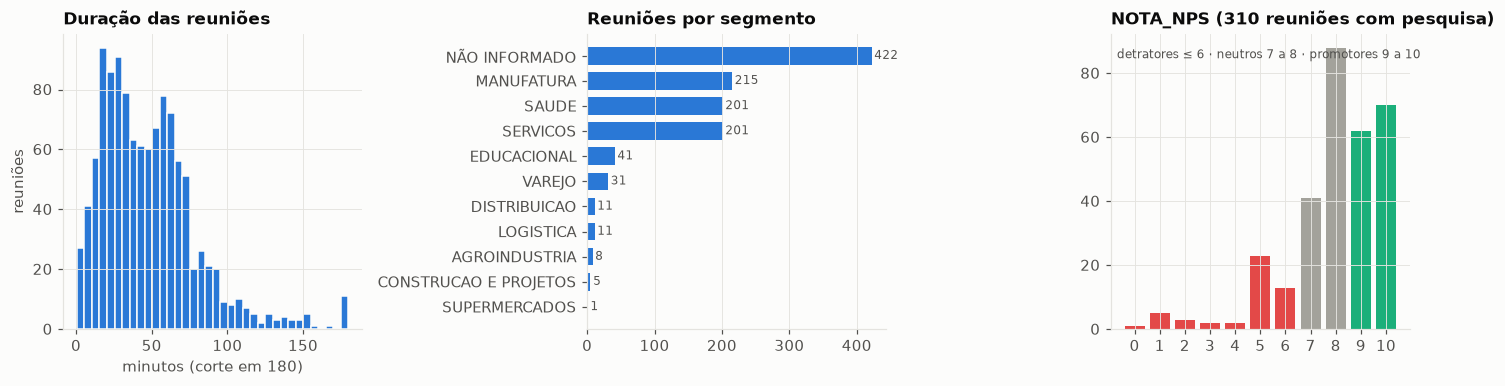

In [3]:
# resumo dos dois conjuntos lado a lado
dev = df[df.conjunto == 'desenvolvimento']
resumo = pd.DataFrame({
    'reuniões': df.groupby('conjunto').size(),
    'duração mediana (min)': df.groupby('conjunto')['DURACAO_MIN'].median().round(1),
    'caracteres medianos': df.groupby('conjunto')['N_CARACTERES'].median().astype(int),
    'com NPS': df.groupby('conjunto')['NOTA_NPS'].count(),
    'NPS médio': df.groupby('conjunto')['NOTA_NPS'].mean().round(2),
    'clientes (CODT)': df.groupby('conjunto')['CODT'].nunique(),
})
display(resumo)

# três gráficos: duração, segmento e notas de NPS
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(df['DURACAO_MIN'].clip(upper=180), bins=36, color=COR[0], edgecolor='#fcfcfb', linewidth=1)
ax[0].set_title('Duração das reuniões'); ax[0].set_xlabel('minutos (corte em 180)'); ax[0].set_ylabel('reuniões')
seg = df['NOME_SEGMENTO'].value_counts().iloc[::-1]
ax[1].barh(seg.index, seg.values, color=COR[0], height=0.7)
ax[1].set_title('Reuniões por segmento'); ax[1].grid(axis='y', visible=False)
for y, v in enumerate(seg.values):
    ax[1].text(v + 4, y, str(v), va='center', color=TINTA2, fontsize=8)
nps = df['NOTA_NPS'].dropna().astype(int).value_counts().sort_index()
ax[2].bar(nps.index, nps.values, color=[COR[7] if n <= 6 else ('#a3a29b' if n <= 8 else COR[2]) for n in nps.index], width=0.8)
ax[2].set_title('NOTA_NPS (310 reuniões com pesquisa)'); ax[2].set_xticks(range(0, 11))
ax[2].text(0.02, 0.95, 'detratores ≤ 6 · neutros 7 a 8 · promotores 9 a 10', transform=ax[2].transAxes, color=TINTA2, fontsize=8, va='top')
plt.tight_layout(); plt.show()

A base é longa e cheia de ruído. A mediana passa de 30 mil caracteres por reunião. A diarização (a parte da transcrição automática que separa quem está falando) quebra frases no meio, entre um locutor e outro. E os nomes de produto aparecem com grafias erradas da transcrição automática ("Totos", "TOTUS", "Proteus", "DataSuite"). Só 310 das 1.147 reuniões têm NPS, e 422 não têm segmento nem faixa de receita. Por isso o NPS entra só como **sinal externo** para validar o score de risco (seção 5). Ele nunca é usado no treino.

## 1.3 Exploração por tópicos (LDA)

Em vez de olhar termos por produto, a gente procurou **temas de conversa**. Para isso usamos o LDA (*Latent Dirichlet Allocation*), um modelo que observa quais palavras costumam aparecer juntas e agrupa essas palavras em tópicos. Cada reunião vira uma mistura desses tópicos. Rodamos o LDA só nas reuniões de desenvolvimento.

Antes, limpamos o texto: tiramos os rótulos de locutor, as marcas de anonimização e uma lista de palavras vazias do português falado ("né", "tá", "aí", "gente"...), que senão dominariam qualquer tópico. Para escolher quantos tópicos usar, comparamos a coerência UMass de cada opção. Essa medida verifica se as 10 palavras principais de cada tópico costumam aparecer nas mesmas reuniões. Quanto maior, mais o tópico faz sentido.

In [4]:
# ferramentas de texto e o LDA do scikit-learn
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# palavras vazias do português falado, que não ajudam a achar tema
PARADAS = set("""
a à ao aos as às até com como da das de dela dele deles do dos e é ela ele eles em entre era essa essas esse
esses esta está estão estava este estes eu foi for há isso isto já la lá lhe mais mas me mesmo meu minha
muito muita muitos na nas não nem no nos nós nossa nosso nossos num numa o os ou para pela pelas pelo pelos
por qual quando que quem se sem ser seu sua são só também te tem tenho ter teu tua tu um uma umas uns você
vocês vai vou vamos ir sim né tá ta aí ai então assim gente aqui ali coisa coisas pra pro pras pros daí dai
bom boa beleza ok entendi exatamente certo legal tipo acho fazer faz fala falar falou sei saber ver olha
olhar porque pode posso consegue conseguir consigo hoje agora depois ainda bem cara tudo todo toda todos todas
ah eh hum uhum oi obrigado obrigada tarde dia perfeito joia show realmente questão parte forma vez nada algum
alguma alguns algumas outro outra outros outras cada dá dar deu estou estamos estar sendo sobre tô tava
ficar fica fico teria seria onde qualquer ia vem vir tinha têm temos precisa preciso deixa deixar lado mim
meio mês ano anos hora horas momento caso exemplo vão foram tava tão aquele aquela aquilo coisinha pouquinho
pouco bastante sempre nunca mesma mesmos lo la vamo opa entendeu entender tranquilo verdade claro sabe
dizer disse falando fazendo tendo vendo quer queria querer gostaria acredito imagino digamos enfim porém
aqui sido seja sejam vamos fosse fazemos faço fez feito ponto vezes dois duas três primeiro primeira
locutor pessoa local empresa ficou acaba acabou ver vejo vê olhando pessoal tal total menos maior tanto
""".split())


# tira rótulos de locutor e marcas de anonimização antes de contar palavras
def texto_limpo(t):
    t = re.sub(r'\[LOCUTOR \d+\]:', ' ', t)
    t = re.sub(r'\[(PESSOA|EMPRESA|LOCAL)\]', ' ', t)
    return t.lower()


# conta as palavras de cada reunião de desenvolvimento
vet_topicos = CountVectorizer(preprocessor=texto_limpo, token_pattern=r'(?u)\b[a-zà-ú]{3,}\b',
                              stop_words=list(PARADAS), min_df=8, max_df=0.45, max_features=6000)
X_dev = vet_topicos.fit_transform(dev['TRANSCRICAO'])
vocab = np.array(vet_topicos.get_feature_names_out())
# em quantas reuniões cada palavra aparece (usado na coerência)
binario = (X_dev > 0).astype(np.int32).tocsc()
df_termo = np.asarray(binario.sum(axis=0)).ravel()


# coerência UMass: nota maior quando as palavras principais de um tópico aparecem juntas
def coerencia_umass(componentes, top=10):
    notas = []
    for linha in componentes:
        idx = linha.argsort()[::-1][:top]
        s = 0.0
        for i in range(1, len(idx)):
            for j in range(i):
                co = binario[:, idx[i]].multiply(binario[:, idx[j]]).sum()
                s += math.log((co + 1) / df_termo[idx[j]])
        notas.append(s / (top * (top - 1) / 2))
    return float(np.mean(notas))


# testa 6, 8, 10 e 12 tópicos e fica com o de maior coerência
busca = {}
for k in [6, 8, 10, 12]:
    lda_k = LatentDirichletAllocation(n_components=k, learning_method='batch', max_iter=30, random_state=SEMENTE)
    lda_k.fit(X_dev)
    busca[k] = (coerencia_umass(lda_k.components_), lda_k)
display(pd.DataFrame({'k': list(busca), 'coerência UMass (maior = melhor)': [round(v[0], 3) for v in busca.values()]}).set_index('k').T)
K = max(busca, key=lambda k: busca[k][0])
lda = busca[K][1]
print('k escolhido:', K)

k,6,8,10,12
coerência UMass (maior = melhor),-0.803,-0.813,-0.928,-0.875


k escolhido: 6


In [5]:
# as 12 palavras mais fortes de cada tópico
termos_topico = {t: list(vocab[lda.components_[t].argsort()[::-1][:12]]) for t in range(K)}
for t, termos in termos_topico.items():
    print(f'T{t}:', ', '.join(termos))

T0: crm, venda, vendedor, vendas, marketing, orçamento, oportunidade, conversas, etapa, negociação, commerce, campanha
T1: escopo, proteus, feira, suporte, ambiente, resolver, teste, fluig, produção, ontem, cronograma, usuários
T2: saúde, office, boleto, banco, vender, contas, back, venda, tecnologia, dinheiro, operadora, fiscal
T3: paciente, médico, prontuário, agendamento, hospital, clínica, convênio, exames, cloud, pacientes, saúde, nuvem
T4: nota, estoque, proteus, ordem, compra, fiscal, produção, entrada, item, cadastro, compras, tabela
T5: colaborador, folha, colaboradores, gestor, documento, avaliação, treinamento, aplicativo, férias, coleta, documentos, assinatura


Os nomes abaixo foram dados por nós, lendo os 12 termos de cada tópico. São a nossa interpretação: o modelo não dá nome a nada.

,tema,termos principais,peso médio,reuniões em que domina
T0,"Vendas, CRM e marketing","crm, venda, vendedor, vendas, marketing, orçamento, oportunidade, conversas, etapa, negociação",0.105,62
T1,Projeto e implantação,"escopo, proteus, feira, suporte, ambiente, resolver, teste, fluig, produção, ontem",0.374,227
T2,Financeiro e back office,"saúde, office, boleto, banco, vender, contas, back, venda, tecnologia, dinheiro",0.192,104
T3,Saúde,"paciente, médico, prontuário, agendamento, hospital, clínica, convênio, exames, cloud, pacientes",0.071,41
T4,"Fiscal, compras e estoque","nota, estoque, proteus, ordem, compra, fiscal, produção, entrada, item, cadastro",0.150,78
T5,RH e gestão de pessoas,"colaborador, folha, colaboradores, gestor, documento, avaliação, treinamento, aplicativo, férias, coleta",0.109,62


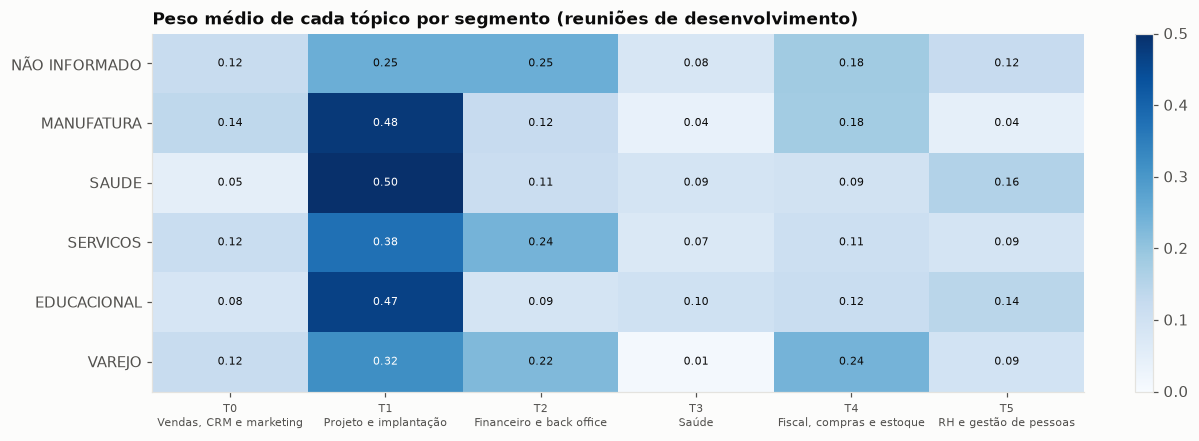

In [6]:
# nomes que demos a cada tópico depois de ler as palavras
NOMES_TOPICO = {
    0: 'Vendas, CRM e marketing',
    1: 'Projeto e implantação',
    2: 'Financeiro e back office',
    3: 'Saúde',
    4: 'Fiscal, compras e estoque',
    5: 'RH e gestão de pessoas',
}
# tópico que mais pesa em cada reunião de desenvolvimento
theta_dev = lda.transform(X_dev)
dev = dev.assign(topico=theta_dev.argmax(axis=1))
dev['tema'] = dev['topico'].map(NOMES_TOPICO)

# tabela com termos, peso médio e quantas reuniões cada tópico domina
tabela_topicos = pd.DataFrame({
    'tema': [NOMES_TOPICO[t] for t in range(K)],
    'termos principais': [', '.join(termos_topico[t][:10]) for t in range(K)],
    'peso médio': theta_dev.mean(axis=0).round(3),
    'reuniões em que domina': [int((dev['topico'] == t).sum()) for t in range(K)],
}, index=[f'T{t}' for t in range(K)])
display(tabela_topicos)

# mapa de calor: peso de cada tópico por segmento (só segmentos com 10 reuniões ou mais)
segs = [s for s in df['NOME_SEGMENTO'].value_counts().index if (dev['NOME_SEGMENTO'] == s).sum() >= 10]
mat = pd.DataFrame(theta_dev, index=dev.index).groupby(dev['NOME_SEGMENTO']).mean().loc[segs]
fig, ax = plt.subplots(figsize=(11, 0.45 * len(segs) + 1.4))
im = ax.imshow(mat.values, cmap='Blues', aspect='auto', vmin=0)
ax.set_xticks(range(K)); ax.set_xticklabels([f'T{t}\n{NOMES_TOPICO[t]}' for t in range(K)], fontsize=7.5)
ax.set_yticks(range(len(segs))); ax.set_yticklabels(segs); ax.grid(False)
for i in range(len(segs)):
    for j in range(K):
        v = mat.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7.5, color='white' if v > mat.values.max() * 0.6 else TINTA)
ax.set_title('Peso médio de cada tópico por segmento (reuniões de desenvolvimento)')
plt.colorbar(im, ax=ax, fraction=0.025); plt.tight_layout(); plt.show()

Os tópicos separam bem o **assunto** das reuniões: implantação de projeto, vendas e CRM, financeiro, fiscal e estoque, saúde e RH. O mapa mostra que cada segmento se apoia em um ou dois temas. Isso ajuda de dois jeitos. Primeiro, o tema dominante vai para o registro de CRM como contexto da reunião. Segundo, dá para comparar os indicadores por tema (seção 3.4). O que os tópicos **não** fazem é dizer se a conversa traz dor, objeção, risco ou oportunidade. Para isso a gente precisa do classificador de trechos.

## 1.4 A arquitetura da versão sequencial (commit `e4d6257`)

No `app/agent.py` daquela versão, o `pipeline_reuniao` era um `SequentialAgent` do Google ADK. Cada agente lia do estado da sessão o resultado que o anterior tinha gravado (a `output_key`) e só começava quando o anterior terminava. Nós recortamos a parte da cadeia que gera o registro de CRM, sem as camadas que vieram depois:

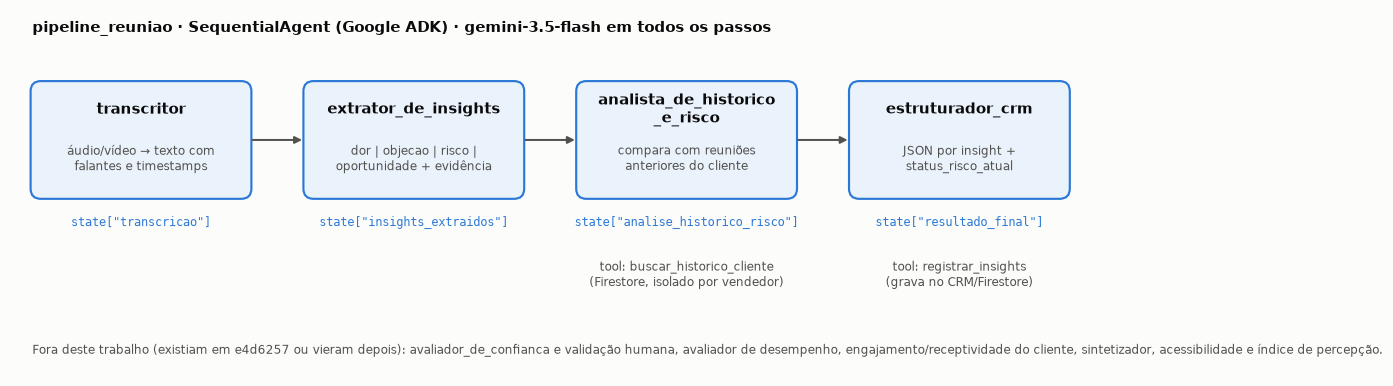

In [7]:
# desenho da cadeia de agentes da versão sequencial
fig, ax = plt.subplots(figsize=(13, 4.3))
ax.set_xlim(0, 13); ax.set_ylim(0, 4.3); ax.axis('off')
etapas = [
    ('transcritor', 'áudio/vídeo → texto com\nfalantes e timestamps', 'transcricao'),
    ('extrator_de_insights', 'dor | objecao | risco |\noportunidade + evidência', 'insights_extraidos'),
    ('analista_de_historico\n_e_risco', 'compara com reuniões\nanteriores do cliente', 'analise_historico_risco'),
    ('estruturador_crm', 'JSON por insight +\nstatus_risco_atual', 'resultado_final'),
]
x0, w, h, y = 0.25, 2.55, 1.35, 2.1
# uma caixa por agente, com a seta para o próximo
for i, (nome, oque, chave) in enumerate(etapas):
    x = x0 + i * 3.2
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.12', fc='#eaf2fc', ec=COR[0], lw=1.4))
    ax.text(x + w / 2, y + h - 0.32, nome, ha='center', va='center', fontsize=9.5, weight='bold', color=TINTA)
    ax.text(x + w / 2, y + 0.45, oque, ha='center', va='center', fontsize=8, color=TINTA2)
    ax.text(x + w / 2, y - 0.3, f'state["{chave}"]', ha='center', va='center', fontsize=7.8, family='monospace', color=COR[0])
    if i < 3:
        ax.annotate('', xy=(x + 3.2, y + h / 2), xytext=(x + w, y + h / 2), arrowprops=dict(arrowstyle='-|>', color=TINTA2, lw=1.3))
ax.text(x0 + 2 * 3.2 + w / 2, 1.05, 'tool: buscar_historico_cliente\n(Firestore, isolado por vendedor)', ha='center', fontsize=7.8, color=TINTA2)
ax.text(x0 + 3 * 3.2 + w / 2, 1.05, 'tool: registrar_insights\n(grava no CRM/Firestore)', ha='center', fontsize=7.8, color=TINTA2)
ax.text(0.25, 4.05, 'pipeline_reuniao · SequentialAgent (Google ADK) · gemini-3.5-flash em todos os passos', fontsize=10, weight='bold', color=TINTA)
ax.text(0.25, 0.25, 'Fora deste trabalho (existiam em e4d6257 ou vieram depois): avaliador_de_confianca e validação humana, avaliador de desempenho, '
        'engajamento/receptividade do cliente, sintetizador, acessibilidade e índice de percepção.', fontsize=7.8, color=TINTA2)
plt.show()

Copiamos os prompts originais do `agent.py` daquela versão (`git show e4d6257:app/agent.py`). A célula abaixo guarda a instrução de cada agente, sem os blocos de catálogo e de regras que o código juntava depois. Em seguida mostramos o começo de cada um:

In [8]:
# instrução original de cada agente em e4d6257, copiada do agent.py
PROMPTS_E4D6257 = {'transcritor': 'Você transcreve reuniões comerciais a partir de áudio ou vídeo. Identifique cada falante de '
                'forma consistente (Falante 1, Falante 2, etc.) e inclua timestamps aproximados a cada troca '
                'de fala. Não resuma, não interprete e não corrija o que foi dito — transcreva fielmente, '
                'incluindo hesitações relevantes ao contexto comercial (ex: "não sei se temos orçamento '
                'agora"). Ao final, segmente o texto em blocos temáticos (abertura, apresentação da dor, '
                'objeções, próximos passos) para facilitar a análise das próximas etapas. Se houver trechos '
                'inaudíveis, marque como [inaudível] em vez de adivinhar o conteúdo.',
 'extrator_de_insights': 'Você analisa transcrições de reuniões comerciais e extrai insights e classifica '
                         'cada um em exatamente um tipo_insight: dor (dor ou necessidade do cliente), '
                         'objecao (objeção a preço, prazo, produto ou condição), risco (sinal de churn ou '
                         'insatisfação) ou oportunidade (oportunidade comercial). O tipo_insight só pode ser '
                         'um destes quatro valores, escritos exatamente assim, em snake_case, sem acento nem '
                         'maiúscula: dor | objecao | risco | oportunidade — nunca outro valor. Para cada '
                         'insight, cite o trecho exato da transcrição que o sustenta e identifique o '
                         'falante. Não infira insights sem base direta no texto — se um trecho for ambíguo, '
                         'extraia mesmo assim, mas deixe a ambiguidade evidente na evidência citada (o '
                         'Avaliador de Confiança trata disso, não você). Para cada insight, verifique também '
                         'se a evidência daquele insight especifico menciona um concorrente: se um nome de '
                         'concorrente aparecer de forma explícita e inequívoca dentro do próprio trecho da '
                         'evidência, coloque-o no campo concorrente_mencionado; em qualquer outro caso — '
                         'inclusive se a menção só existir em outro trecho da transcrição, ou exigir inferir '
                         'algo a partir de contexto indireto — o campo é null. Proibido inferir ou supor um '
                         'concorrente que não esteja nomeado literalmente na evidência desse insight. '
                         'Retorne uma lista em JSON com os campos: tipo_insight, insight, evidencia, '
                         'falante, timestamp_aproximado, concorrente_mencionado, produto_totvs_mencionado.',
 'analista_de_historico_e_risco': 'Você mantém a visão histórica de cada cliente no NousSight. Ao receber os '
                                  'insights validados de uma nova reunião, compare-os com o histórico de '
                                  'reuniões anteriores desse mesmo cliente (quando disponível). A mensagem '
                                  'original desta reunião traz cliente_id e reuniao_id - ao chamar '
                                  'buscar_historico_cliente, passe o cliente_id e também o reuniao_id desta '
                                  'reunião no parâmetro reuniao_id_atual (assim esta própria reunião, ou uma '
                                  'tentativa anterior dela, fica fora do histórico). A tool já devolve só o '
                                  'histórico do vendedor desta sessão (cliente_id é texto livre, sem '
                                  'unicidade garantida entre vendedores, e o isolamento é feito pela '
                                  'sessão): nunca tente informar ou deduzir um vendedor. Identifique: se '
                                  'sinais de risco já existentes pioraram, melhoraram ou se mantiveram; se '
                                  'novas objeções ou dores surgiram; se há uma tendência (ex: 3 reuniões '
                                  'seguidas mencionando o mesmo problema não resolvido). Insights ainda '
                                  'pendentes de validação humana entram na análise como "não confirmados" e '
                                  'não devem, sozinhos, mudar o status de risco do cliente. Retorne um '
                                  'resumo estruturado com: cliente, status_risco_atual (baixo | medio | '
                                  'alto), mudanca_desde_ultima_reuniao, insights_recorrentes.\n'
                                  '\n'
                                  'Insights com avaliação de confiança:\n'
                                  '{insights_com_confianca}',
 'estruturador_crm': 'Você formata a saída combinada do Avaliador de Confiança e do Analista de Histórico e '
                     'Risco em um objeto JSON pronto para o CRM. Mapeie cada insight para os campos: '
                     'cliente, tipo_insight (dor | objecao | risco | oportunidade), categoria_crm (historico '
                     '| risco | proxima_acao | tendencia), resumo, evidencia, timestamp_aproximado, falante, '
                     'concorrente_mencionado, produto_totvs_mencionado, score_confianca, status (validado | '
                     'pendente_validacao). tipo_insight (a classificação do insight), timestamp_aproximado '
                     '(o instante do áudio onde a evidência foi dita), falante (quem disse a evidência), '
                     'concorrente_mencionado (nome do concorrente citado na evidência, ou null) e '
                     'produto_totvs_mencionado (produto TOTVS citado na evidência, ou null) já vêm prontos '
                     'em cada insight de entrada — foram gerados pelo Extrator de Insights e preservados '
                     'pelo Avaliador de Confiança. Copie os cinco campos para TODO insight do JSON final, '
                     'exatamente como vieram na entrada, sem renomear nem descartar nenhum dos cinco — eles '
                     'não são opcionais e não devem ser omitidos mesmo quando parecerem redundantes com o '
                     'resumo ou a evidência; concorrente_mencionado e produto_totvs_mencionado em especial '
                     'têm que aparecer explicitamente como null quando não houver menção, nunca ser omitidos '
                     'do insight. REGRA DE MAPEAMENTO de categoria_crm (não é escolha livre — derive sempre '
                     'do tipo_insight do insight): dor → historico; objecao → risco; risco → risco; '
                     'oportunidade → proxima_acao. Não há exceção: nunca use tendencia (a recorrência de '
                     'temas já fica registrada em insights_recorrentes, separada da categoria) nem qualquer '
                     'outro valor, e nunca altere o tipo_insight para justificar a categoria. Se o insight '
                     'de entrada tiver o campo pergunta_validacao, inclua-o também no insight final, sem '
                     'alterar o texto. Inclua também um bloco separado com o status_risco_atual do cliente '
                     'vindo do Analista de Histórico e Risco. Não altere o conteúdo ou reinterprete os '
                     'insights — apenas reformate. Se um campo obrigatório estiver ausente na entrada, '
                     'deixe-o como null em vez de inventar um valor. Ao chamar a tool registrar_insights, '
                     'passe também a avaliação de desempenho do vendedor (abaixo) como o parâmetro '
                     'avaliacao_desempenho_vendedor, sem alterar o conteúdo dela (padroes_detectados, notas '
                     'e feedback, exatamente como estão) — avaliacao_desempenho_vendedor é um dado sobre o '
                     'vendedor, separado dos insights sobre o cliente. O vendedor é identificado pela '
                     'própria sessão: a tool não tem parâmetro de vendedor, e você nunca informa nem inventa '
                     'um vendedor_id.\n'
                     '\n'
                     'Insights com avaliação de confiança:\n'
                     '{insights_com_confianca}\n'
                     '\n'
                     'Análise de histórico e risco:\n'
                     '{analise_historico_risco}\n'
                     '\n'
                     'Avaliação de desempenho do vendedor:\n'
                     '{avaliacao_desempenho_vendedor}'}

# mostra o começo de cada prompt
for nome, texto in PROMPTS_E4D6257.items():
    print(f'--- {nome} ({len(texto)} caracteres) ---')
    print(texto[:520], '...\n')

--- transcritor (606 caracteres) ---
Você transcreve reuniões comerciais a partir de áudio ou vídeo. Identifique cada falante de forma consistente (Falante 1, Falante 2, etc.) e inclua timestamps aproximados a cada troca de fala. Não resuma, não interprete e não corrija o que foi dito — transcreva fielmente, incluindo hesitações relevantes ao contexto comercial (ex: "não sei se temos orçamento agora"). Ao final, segmente o texto em blocos temáticos (abertura, apresentação da dor, objeções, próximos passos) para facilitar a análise das próximas etapas. ...

--- extrator_de_insights (1435 caracteres) ---
Você analisa transcrições de reuniões comerciais e extrai insights e classifica cada um em exatamente um tipo_insight: dor (dor ou necessidade do cliente), objecao (objeção a preço, prazo, produto ou condição), risco (sinal de churn ou insatisfação) ou oportunidade (oportunidade comercial). O tipo_insight só pode ser um destes quatro valores, escritos exatamente assim, em snake_case, sem

### Como cada agente foi reimplementado aqui

Na versão original, cada passo chamava o Gemini. Como o foco da disciplina é o modelo estatístico, a gente transformou cada agente numa função Python que **segue o mesmo contrato** do original: as mesmas chaves de entrada e saída e os mesmos campos.

| Agente (e4d6257) | O que fazia com LLM | Reimplementação neste notebook |
|---|---|---|
| `transcritor` | áudio → texto com falantes | A base já vem transcrita: o passo só normaliza as falas (`[LOCUTOR n]: texto`), como no app `pipeline_reuniao_transcrita`, que pulava o transcritor |
| `extrator_de_insights` | lista de insights com `tipo_insight`, evidência literal, falante, concorrente e produto TOTVS | corta a transcrição em trechos, classifica cada trecho com o modelo da seção 2 e preenche concorrente e produto pelo catálogo de `e4d6257`, só quando o nome está escrito no próprio trecho (regras de a até f do prompt original) |
| `analista_de_historico_e_risco` | compara com o histórico do cliente e devolve `status_risco_atual` (baixo/médio/alto), mudança e recorrências | usa as reuniões anteriores do mesmo `CODT`, o score de risco da seção 3 e os temas repetidos |
| `estruturador_crm` | JSON pronto para o CRM, `categoria_crm` derivada do tipo | a mesma regra fixa: dor→historico, objecao→risco, risco→risco, oportunidade→proxima_acao |

Os campos `score_confianca`, `status` e `pergunta_validacao` do estruturador original dependiam do avaliador de confiança, então **não existem nesta versão**.

In [9]:
# catálogo de concorrentes e produtos TOTVS de e4d6257 (catalogo/totvs_catalogo.json)
catalogo = {'versao': 1,
 'concorrentes': [{'nome_canonico': 'SAP',
                   'apelidos': [],
                   'segmento': 'ERP',
                   'exige_contexto': False,
                   'verificado': False},
                  {'nome_canonico': 'Oracle NetSuite',
                   'apelidos': ['NetSuite', 'Net Suite'],
                   'segmento': 'ERP',
                   'exige_contexto': False,
                   'verificado': False},
                  {'nome_canonico': 'Senior',
                   'apelidos': ['Senior Sistemas'],
                   'segmento': 'ERP / Gestao de pessoas',
                   'exige_contexto': True,
                   'verificado': False},
                  {'nome_canonico': 'Sankhya',
                   'apelidos': [],
                   'segmento': 'ERP',
                   'exige_contexto': False,
                   'verificado': False},
                  {'nome_canonico': 'Microsoft Dynamics',
                   'apelidos': ['Dynamics 365'],
                   'segmento': 'ERP / CRM',
                   'exige_contexto': False,
                   'verificado': False},
                  {'nome_canonico': 'Omie',
                   'apelidos': [],
                   'segmento': 'ERP para pequenas empresas',
                   'exige_contexto': False,
                   'verificado': False},
                  {'nome_canonico': 'Conta Azul',
                   'apelidos': ['ContaAzul'],
                   'segmento': 'Gestao financeira para pequenas empresas',
                   'exige_contexto': True,
                   'verificado': False},
                  {'nome_canonico': 'Linx',
                   'apelidos': [],
                   'segmento': 'Varejo',
                   'exige_contexto': False,
                   'verificado': False},
                  {'nome_canonico': 'Bling',
                   'apelidos': [],
                   'segmento': 'ERP para e-commerce',
                   'exige_contexto': True,
                   'verificado': False}],
 'produtos_totvs': [{'nome_canonico': 'Protheus',
                     'apelidos': ['TOTVS Protheus'],
                     'linha': 'ERP',
                     'verificado': False,
                     'exige_contexto': False},
                    {'nome_canonico': 'RM',
                     'apelidos': ['TOTVS RM'],
                     'linha': 'ERP',
                     'exige_contexto': True,
                     'verificado': False},
                    {'nome_canonico': 'Datasul',
                     'apelidos': ['TOTVS Datasul'],
                     'linha': 'ERP',
                     'verificado': False,
                     'exige_contexto': False},
                    {'nome_canonico': 'Logix',
                     'apelidos': ['TOTVS Logix'],
                     'linha': 'ERP',
                     'exige_contexto': True,
                     'verificado': False},
                    {'nome_canonico': 'Fluig',
                     'apelidos': ['TOTVS Fluig'],
                     'linha': 'Plataforma de processos e colaboracao',
                     'verificado': False,
                     'exige_contexto': False},
                    {'nome_canonico': 'RD Station',
                     'apelidos': [],
                     'linha': 'Marketing e vendas',
                     'verificado': False,
                     'exige_contexto': False},
                    {'nome_canonico': 'TOTVS Techfin',
                     'apelidos': ['Techfin'],
                     'linha': 'Servicos financeiros',
                     'verificado': False,
                     'exige_contexto': False}]}


# monta uma busca por nome para cada produto ou concorrente, incluindo os apelidos
def _padroes(itens):
    saida = []
    for it in itens:
        nomes = [it['nome_canonico']] + it['apelidos']
        for n in nomes:
            exige = it['exige_contexto'] and n == it['nome_canonico']
            saida.append((it['nome_canonico'], re.compile(r'(?<![\wÀ-ú])' + re.escape(n) + r'(?![\wÀ-ú])', re.I if not exige else 0), exige))
    return saida


# buscas prontas para produtos TOTVS e concorrentes
PADROES_PRODUTO = _padroes(catalogo['produtos_totvs'])
PADROES_CONCORRENTE = _padroes(catalogo['concorrentes'])


def citados(texto, padroes):
    """Nomes do catálogo escritos literalmente no texto. Itens 'exige contexto' (RM, Logix, Senior,
    Conta Azul, Bling) só contam com a grafia exata e a palavra sistema/TOTVS por perto."""
    achados = []
    for canonico, rx, exige in padroes:
        for m in rx.finditer(texto):
            if exige:
                janela = texto[max(0, m.start() - 60): m.end() + 60].lower()
                if not re.search(r'totvs|sistema|erp', janela):
                    continue
            achados.append(canonico)
    return achados


# formato de cada fala na base: [LOCUTOR n]: texto
_FALA = re.compile(r'^\[(LOCUTOR \d+)\]:\s*(.*)$')


def transcritor(transcricao):
    """Passo 1: normaliza a transcrição em falas (falante, texto)."""
    falas = []
    for linha in transcricao.split('\n'):
        m = _FALA.match(linha.strip())
        if m and m.group(2).strip():
            falas.append((m.group(1), m.group(2).strip()))
    return falas


def cortar_trechos(falas, minimo=150, maximo=480):
    """Junta falas consecutivas até `minimo` caracteres: a diarização da base quebra frases entre
    locutores, então um trecho de várias falas lê melhor que uma fala isolada."""
    trechos, atual, tam = [], [], 0
    for falante, texto in falas:
        atual.append((falante, texto))
        tam += len(texto)
        if tam >= minimo:
            bloco = '\n'.join(f'[{f}]: {t}' for f, t in atual)[:maximo]
            principal = Counter({f: 0 for f, _ in atual})
            for f, t in atual:
                principal[f] += len(t)
            trechos.append({'trecho': bloco, 'falante': principal.most_common(1)[0][0]})
            atual, tam = [], 0
    return trechos

## 1.5 Linha do tempo da execução sequencial

Na versão sequencial, o tempo de uma reunião é a **soma** dos passos. O estruturador não pode começar antes do analista, que espera o extrator, que espera o transcritor. O diagrama abaixo mostra esse encadeamento. As posições são relativas e não têm escala em segundos, porque não temos medições guardadas das chamadas ao Gemini daquela época. A linha do tempo **medida**, com os segundos de cada passo da nossa versão local, está em 4.2, depois que o modelo é escolhido.

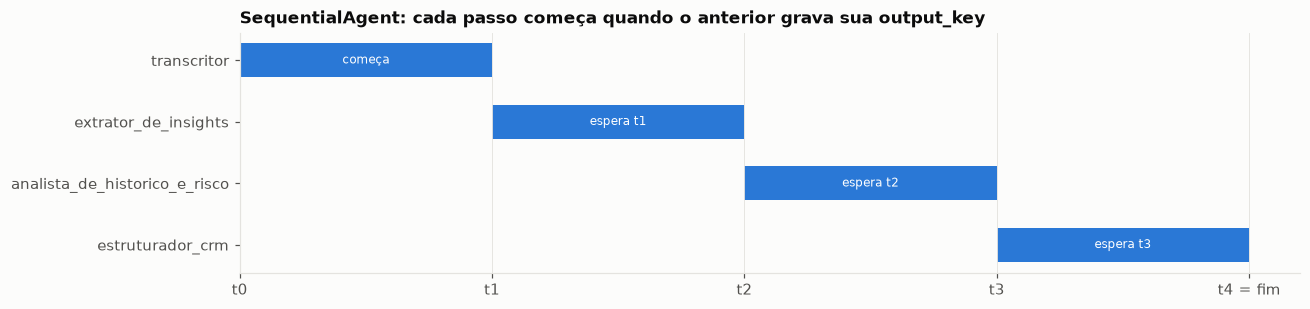

In [10]:
# diagrama: cada passo só começa quando o anterior termina
fig, ax = plt.subplots(figsize=(12, 2.9))
passos = ['transcritor', 'extrator_de_insights', 'analista_de_historico_e_risco', 'estruturador_crm']
inicio = 0
for i, p in enumerate(passos):
    ax.barh(len(passos) - 1 - i, 1, left=inicio, color=COR[0], height=0.55)
    ax.text(inicio + 0.5, len(passos) - 1 - i, f'espera t{i}' if i else 'começa', ha='center', va='center', color='white', fontsize=8)
    inicio += 1
ax.set_yticks(range(len(passos))); ax.set_yticklabels(passos[::-1])
ax.set_xticks(range(5)); ax.set_xticklabels(['t0', 't1', 't2', 't3', 't4 = fim'])
ax.set_title('SequentialAgent: cada passo começa quando o anterior grava sua output_key'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

Foi esse jeito de rodar em fila que levou à troca para `ParallelAgent` na tarde de 03/10: o tempo de resposta cresce a cada agente colocado na fila, mesmo quando dois passos não dependem um do outro. Na versão completa de `e4d6257`, desempenho do vendedor, engajamento e síntese também rodavam em fila antes do extrator. Já na cadeia que recortamos aqui, as quatro dependências são reais: o extrator precisa da transcrição, o analista precisa dos insights e o estruturador precisa dos dois. Então, neste recorte, rodar em sequência não desperdiça nada.

<a id="2"></a>
# 2. Modelo final e justificativa

## 2.1 Unidade de análise e classes

O extrator antigo classificava cada insight como `dor`, `objecao`, `risco` ou `oportunidade`. Para treinar um modelo local, a gente usou como unidade o **trecho**: falas seguidas que somam pelo menos 150 caracteres, como em 1.4. O alvo é a `categoria_crm` que o estruturador tirava do tipo, mais a classe `nenhum` para trecho sem insight:

| categoria_crm (alvo) | tipos do extrator antigo |
|---|---|
| `historico` | dor |
| `risco` | objecao, risco |
| `proxima_acao` | oportunidade |
| `nenhum` | trecho sem insight (a maioria da conversa) |

Juntamos objeção e risco porque o próprio estruturador fazia isso, e porque assim evitamos duas classes com só 7 ou 8 exemplos cada.

## 2.2 Amostra e método de rotulagem

1. **Sorteio inicial.** Um trecho por reunião: 60 reuniões de índice par (semente 2110) e 40 de índice ímpar (semente 1021). 70% dos trechos tinham alguma palavra-pista ("planilha", "caro", "proposta", "suporte"...) e 30% não tinham.
2. **Pré-rótulo com apoio de IA.** Um assistente de IA (o que usamos no desenvolvimento, não o Gemini do pipeline) leu cada trecho com as definições de `tipo_insight` do prompt do extrator antigo e sugeriu um tipo ou `nenhum`.
3. **Complemento por classe.** No sorteio inicial, 41 dos 60 trechos saíram `nenhum`, com só 4 ou 5 por tipo. Então sorteamos mais 66 trechos de reuniões pares e 36 de ímpares, cada um com palavras-pista de uma classe, e pré-rotulamos do mesmo jeito. A pista só serve para guiar o sorteio: vários trechos com "proposta" ou "problema" acabaram como `nenhum`.
4. **Seleção balanceada.** Do que foi rotulado, sorteamos cotas por classe: **60 trechos de desenvolvimento** e **40 de holdout**, cada um de uma reunião diferente.
5. **Revisão feita pelo grupo.** A gente revisou 15 trechos do desenvolvimento, sorteados por classe (4 de cada tipo de insight e 3 `nenhum`), vendo o pré-rótulo. Discordamos de 4 (concordância de **11/15 = 73%**) e indicamos o rótulo certo, que ficou no lugar do rótulo sugerido pela IA.

Como a amostra foi reforçada com trechos de insight, a proporção de classes **não** é a da base. Numa reunião de verdade, a grande maioria dos trechos é `nenhum`. Então as métricas por classe abaixo valem para essa amostra balanceada. O efeito da proporção real aparece na seção 5.

In [11]:
# lê a amostra rotulada e aplica a mesma máscara de nomes
amostra = pd.read_csv(PASTA / 'amostra_rotulada.csv')
amostra['trecho'] = amostra['trecho'].map(mascarar)
print(pd.crosstab(amostra['categoria_crm'], amostra['conjunto'], margins=True).to_string())
# trechos revisados pelo grupo e onde a revisão discordou do pré-rótulo
rev = amostra[amostra['revisado_grupo']]
print(f"\nrevisão humana: {len(rev)} trechos, {int((rev['tipo_insight'] == rev['tipo_insight_llm']).sum())} concordâncias")
display(rev.loc[rev['tipo_insight'] != rev['tipo_insight_llm'], ['id_trecho', 'tipo_insight_llm', 'tipo_insight', 'trecho']])

conjunto       desenvolvimento  holdout  All
categoria_crm                               
historico                   14        8   22
nenhum                      16       13   29
proxima_acao                16       10   26
risco                       14        9   23
All                         60       40  100



revisão humana: 15 trechos, 11 concordâncias


,id_trecho,tipo_insight_llm,tipo_insight,trecho
27,XD05,dor,oportunidade,"[LOCUTOR 1]: Tá bom, entendi. E aí [LOCAL] vão ter uma empresa que vai fazer todo o projeto de desmontagem, tudo isso daí.\n[LOCUTOR 2]: Tá, tem tudo mais, ..."
37,XO02,objecao,dor,"[LOCUTOR 9]: E o problema é que a gente tem até uma cláusula, consta isso em propostas, que a [EMPRESA] pode estar faturando pelo CNPJ [PESSOA] [EMPRESA] ma..."
41,XO09,nenhum,oportunidade,"[LOCUTOR 40]: [LOCAL], [PESSOA]. Eu só gostaria de trazer justamente a questão da própria logística em si, principalmente quando a gente está falando agora ..."
47,XO17,oportunidade,nenhum,"[LOCUTOR 53]: Não, [PESSOA] aí pode deixar que eu articulo aqui, a gente tem uma [LOCAL], aí ela orienta, né, e gera a proposta. Beleza,\n[LOCUTOR 43]: tran..."


As quatro discordâncias mostram onde o pré-rótulo erra. A IA viu "dor" numa descrição de expansão (XD05: uma empresa nova que vai precisar de controle, o que é oportunidade). Tratou como "nenhum" um cliente que puxa o assunto WMS (XO09, oportunidade). Viu oportunidade numa conversa interna sobre gerar proposta (XO17, nenhum). E chamou de objeção um problema na emissão de notas (XO02, dor). Três das quatro envolvem a fronteira entre **oportunidade** e as outras classes. É o mesmo tipo de dúvida que a camada de confiança, criada depois, tentava sinalizar.

## 2.3 Modelos comparados

A gente comparou quatro opções:

1. **TF-IDF + Naive Bayes multinomial.** O TF-IDF transforma cada trecho numa lista de números: cada palavra (ou pedaço de palavra) ganha um peso, que é alto quando ela aparece no trecho e é rara no resto da amostra. O Naive Bayes usa esses pesos para calcular a probabilidade de cada classe, supondo que cada palavra contribui por conta própria.
2. **TF-IDF + SVM linear** (`LinearSVC`, com pesos de classe balanceados). O SVM procura a fronteira que melhor separa as classes a partir desses mesmos pesos.
3. **LLM extrator da versão antiga** (`extrator_de_insights` de `e4d6257`, sem avaliador de confiança e sem conferência literal da evidência). Ver 2.4.
4. **Regra de palavras-pista**, como comparação bem simples: escolhe a classe cuja lista de pistas aparece mais vezes no trecho. Se não aparece nenhuma pista, o trecho vira `nenhum`.

Para o Naive Bayes e o SVM testamos três jeitos de representar o texto: palavras soltas e pares de palavras, só palavras soltas, e pedaços de 3 a 5 caracteres (os n-gramas de caracteres, que aguentam melhor os erros de grafia da transcrição). Ficamos com o que teve o melhor F1 na validação cruzada.

O **F1** junta duas medidas numa nota de 0 a 1: a precisão (dos trechos que o modelo marcou numa classe, quantos eram mesmo dela) e o recall (dos trechos daquela classe, quantos o modelo encontrou). O **F1 macro** é a média do F1 das quatro classes, então uma classe pequena pesa o mesmo que uma grande.

Com só 60 exemplos de treino, usamos **validação cruzada estratificada com 5 partes (5-fold), repetida 20 vezes**. Na prática: dividimos os 60 trechos em 5 partes com a mesma mistura de classes, treinamos em 4 partes e testamos na que sobrou, trocando a parte de teste a cada rodada. Repetimos tudo 20 vezes com sorteios diferentes. São 100 ajustes por modelo, o que mostra a média e também o quanto o resultado varia. O holdout fica guardado até a seção 5.

In [12]:
# modelos e métricas do scikit-learn
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import (precision_recall_fscore_support, f1_score, accuracy_score,
                             confusion_matrix, classification_report)

CLASSES = ['historico', 'risco', 'proxima_acao', 'nenhum']


# limpa o trecho antes de virar números
def texto_trecho(t):
    t = re.sub(r'\[LOCUTOR \d+\]:', ' ', t)
    t = re.sub(r'\[(PESSOA|EMPRESA|LOCAL)\]', ' ', t)
    return re.sub(r'\s+', ' ', t.lower())


# TF-IDF por palavras
def tfidf_palavras(ngramas=(1, 1)):
    return TfidfVectorizer(preprocessor=texto_trecho, ngram_range=ngramas, sublinear_tf=True,
                           token_pattern=r'(?u)\b[a-zà-ú0-9]{2,}\b')


# TF-IDF por pedaços de 3 a 5 letras, que aguenta erro de grafia
def tfidf_caracteres():
    return TfidfVectorizer(preprocessor=texto_trecho, analyzer='char_wb', ngram_range=(3, 5), sublinear_tf=True, min_df=2)


# as seis combinações testadas: 3 representações para cada modelo
VARIANTES = {
    ('TF-IDF + Naive Bayes', 'palavras 1-2', 'alpha=0.3'): lambda: make_pipeline(tfidf_palavras((1, 2)), MultinomialNB(alpha=0.3)),
    ('TF-IDF + Naive Bayes', 'palavras 1', 'alpha=0.3'): lambda: make_pipeline(tfidf_palavras(), MultinomialNB(alpha=0.3)),
    ('TF-IDF + Naive Bayes', 'caracteres 3-5', 'alpha=0.1'): lambda: make_pipeline(tfidf_caracteres(), MultinomialNB(alpha=0.1)),
    ('TF-IDF + SVM linear', 'palavras 1-2', 'C=1'): lambda: make_pipeline(tfidf_palavras((1, 2)), LinearSVC(C=1.0, class_weight='balanced')),
    ('TF-IDF + SVM linear', 'palavras 1', 'C=1'): lambda: make_pipeline(tfidf_palavras(), LinearSVC(C=1.0, class_weight='balanced')),
    ('TF-IDF + SVM linear', 'caracteres 3-5', 'C=0.5'): lambda: make_pipeline(tfidf_caracteres(), LinearSVC(C=0.5, class_weight='balanced')),
}

# palavras-pista de cada classe, usadas pela regra simples
PISTAS_CLASSE = {
    'historico': ['manual', 'planilha', 'retrabalho', 'dificuldade', 'não consigo', 'demora', 'na mão', 'controle', 'dor'],
    'risco': ['caro', 'preço', 'valor', 'cancelar', 'insatisf', 'reclama', 'problema', 'chamado', 'suporte',
              'trava', 'não está clar', 'suspender', 'concorrente', 'custo'],
    'proxima_acao': ['proposta', 'interesse', 'próximo passo', 'contratar', 'expandir', 'ampliar', 'demonstração', 'avançar'],
}


# regra simples: vence a classe com mais pistas no trecho
class RegraPistas:
    def fit(self, X, y):
        return self

    def predict(self, X):
        saida = []
        for t in X:
            t = t.lower()
            contagem = {c: sum(t.count(p) for p in ps) for c, ps in PISTAS_CLASSE.items()}
            melhor = max(contagem, key=contagem.get)
            saida.append(melhor if contagem[melhor] > 0 else 'nenhum')
        return np.array(saida)


# separa treino (desenvolvimento) e teste (holdout); a validação cruzada usa 5 partes, 20 vezes
treino = amostra[amostra.conjunto == 'desenvolvimento'].reset_index(drop=True)
teste = amostra[amostra.conjunto == 'holdout'].reset_index(drop=True)
X_tr, y_tr = treino['trecho'].values, treino['categoria_crm'].values
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=SEMENTE)

# configuração de cada família escolhida só pela validação cruzada do desenvolvimento
busca_cfg = []
for (familia, features, hiper), fabrica in VARIANTES.items():
    f1s = [f1_score(y_tr[b], fabrica().fit(X_tr[a], y_tr[a]).predict(X_tr[b]), average='macro', labels=CLASSES, zero_division=0)
           for a, b in rskf.split(X_tr, y_tr)]
    busca_cfg.append({'família': familia, 'features': features, 'hiperparâmetro': hiper, 'F1 macro CV': np.mean(f1s), 'desvio': np.std(f1s)})
busca_cfg = pd.DataFrame(busca_cfg)
display(busca_cfg.round(3))
# guarda a melhor configuração de cada modelo
MODELOS = {}
for familia, grupo in busca_cfg.groupby('família'):
    melhor = grupo.loc[grupo['F1 macro CV'].idxmax()]
    MODELOS[familia] = VARIANTES[(familia, melhor['features'], melhor['hiperparâmetro'])]
    print(f"{familia}: {melhor['features']}, {melhor['hiperparâmetro']}")

# validação cruzada de cada modelo escolhido e da regra
linhas, preds_cv = [], {}
for nome, fabrica in list(MODELOS.items()) + [('Regra de palavras-pista', lambda: RegraPistas())]:
    f1s, accs = [], []
    for i_tr, i_te in rskf.split(X_tr, y_tr):
        m = fabrica().fit(X_tr[i_tr], y_tr[i_tr])
        p = m.predict(X_tr[i_te])
        f1s.append(f1_score(y_tr[i_te], p, average='macro', labels=CLASSES, zero_division=0))
        accs.append(accuracy_score(y_tr[i_te], p))
    preds_cv[nome] = cross_val_predict(fabrica(), X_tr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=SEMENTE)) \
        if nome != 'Regra de palavras-pista' else RegraPistas().predict(X_tr)
    pr, rc, f1, _ = precision_recall_fscore_support(y_tr, preds_cv[nome], labels=CLASSES, average='macro', zero_division=0)
    linhas.append({'modelo': nome, 'F1 macro (média 100 folds)': np.mean(f1s), 'desvio': np.std(f1s),
                   'acurácia (média)': np.mean(accs), 'precisão macro*': pr, 'recall macro*': rc, 'F1 macro*': f1})
# a linha do LLM fica vazia (ver 2.4)
linhas.append({'modelo': 'LLM extrator antigo (Gemini)', 'F1 macro (média 100 folds)': np.nan, 'desvio': np.nan,
               'acurácia (média)': np.nan, 'precisão macro*': np.nan, 'recall macro*': np.nan, 'F1 macro*': np.nan})
comparacao = pd.DataFrame(linhas).set_index('modelo').round(3)
display(comparacao)
print('* calculado sobre as predições fora da dobra de uma 5-fold (cada trecho previsto uma vez)')

,família,features,hiperparâmetro,F1 macro CV,desvio
0,TF-IDF + Naive Bayes,palavras 1-2,alpha=0.3,0.270,0.105
1,TF-IDF + Naive Bayes,palavras 1,alpha=0.3,0.302,0.103
2,TF-IDF + Naive Bayes,caracteres 3-5,alpha=0.1,0.317,0.100
3,TF-IDF + SVM linear,palavras 1-2,C=1,0.290,0.109
4,TF-IDF + SVM linear,palavras 1,C=1,0.332,0.110
5,TF-IDF + SVM linear,caracteres 3-5,C=0.5,0.319,0.109


TF-IDF + Naive Bayes: caracteres 3-5, alpha=0.1
TF-IDF + SVM linear: palavras 1, C=1


,F1 macro (média 100 folds),desvio,acurácia (média),precisão macro*,recall macro*,F1 macro*
modelo,,,,,,
TF-IDF + Naive Bayes,0.317,0.10,0.352,0.345,0.359,0.337
TF-IDF + SVM linear,0.332,0.11,0.372,0.380,0.379,0.358
Regra de palavras-pista,0.520,0.16,0.533,0.549,0.538,0.535
LLM extrator antigo (Gemini),NaN,NaN,NaN,NaN,NaN,NaN


* calculado sobre as predições fora da dobra de uma 5-fold (cada trecho previsto uma vez)


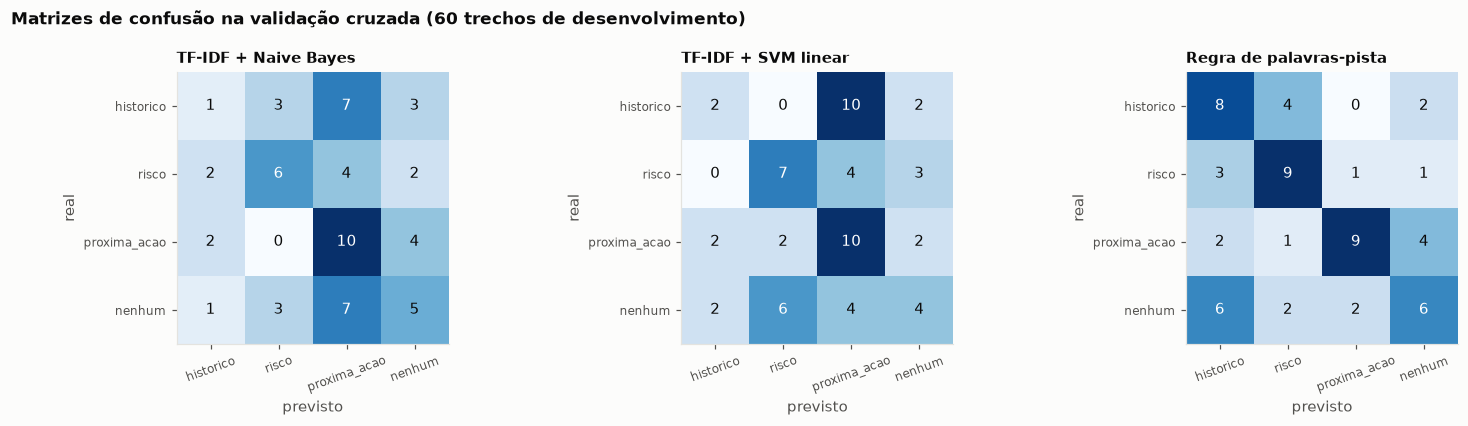

=== TF-IDF + Naive Bayes ===
              precision    recall  f1-score   support

   historico       0.17      0.07      0.10        14
       risco       0.50      0.43      0.46        14
proxima_acao       0.36      0.62      0.45        16
      nenhum       0.36      0.31      0.33        16

    accuracy                           0.37        60
   macro avg       0.35      0.36      0.34        60
weighted avg       0.35      0.37      0.34        60

=== TF-IDF + SVM linear ===
              precision    recall  f1-score   support

   historico       0.33      0.14      0.20        14
       risco       0.47      0.50      0.48        14
proxima_acao       0.36      0.62      0.45        16
      nenhum       0.36      0.25      0.30        16

    accuracy                           0.38        60
   macro avg       0.38      0.38      0.36        60
weighted avg       0.38      0.38      0.36        60



In [13]:
# matrizes de confusão: a linha é a classe real, a coluna é a prevista
fig, axs = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, nome in zip(axs, ['TF-IDF + Naive Bayes', 'TF-IDF + SVM linear', 'Regra de palavras-pista']):
    cm = confusion_matrix(y_tr, preds_cv[nome], labels=CLASSES)
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=cm.max()); ax.grid(False)
    ax.set_xticks(range(4)); ax.set_xticklabels(CLASSES, rotation=20, fontsize=8)
    ax.set_yticks(range(4)); ax.set_yticklabels(CLASSES, fontsize=8)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() * 0.55 else TINTA)
    ax.set_title(nome, fontsize=10); ax.set_xlabel('previsto'); ax.set_ylabel('real')
plt.suptitle('Matrizes de confusão na validação cruzada (60 trechos de desenvolvimento)', x=0.01, ha='left', weight='bold')
plt.tight_layout(); plt.show()

# relatório por classe de cada modelo
for nome in MODELOS:
    print(f'=== {nome} ===')
    print(classification_report(y_tr, preds_cv[nome], labels=CLASSES, digits=2, zero_division=0))

## 2.4 O LLM extrator da versão antiga

A função abaixo monta o prompt do `extrator_de_insights` de `e4d6257` do jeito que ele estava, com duas diferenças: tiramos a frase que passava as dúvidas para o avaliador de confiança (camada fora deste recorte) e os blocos de catálogo, que aqui são aplicados por código. Ela usa as credenciais padrão do ambiente (Application Default Credentials). **Nenhuma chave ou projeto fica escrito no notebook**: o projeto vem da variável `GOOGLE_CLOUD_PROJECT`.

Antes de rodar os 60 trechos, uma chamada curta testa se o modelo responde. Se não responder, a célula continua sem ele.

In [14]:
# prompt do extrator antigo, sem a frase do avaliador de confiança
INSTRUCAO_EXTRATOR = re.sub(r"\s*\(o Avaliador de Confiança trata disso, não você\)", '', PROMPTS_E4D6257['extrator_de_insights'])
MAPA_TIPO = {'dor': 'historico', 'objecao': 'risco', 'risco': 'risco', 'oportunidade': 'proxima_acao'}


# manda um trecho ao Gemini e devolve a classe mais citada nos insights
def extrator_llm_antigo(trecho, cliente):
    prompt = INSTRUCAO_EXTRATOR + '\n\nTranscrição da reunião:\n' + trecho
    r = cliente.models.generate_content(model='gemini-3.5-flash', contents=prompt)
    bruto = re.sub(r'^```(?:json)?|```$', '', r.text.strip(), flags=re.M)
    insights = json.loads(bruto) if bruto.strip().startswith('[') else []
    if not insights:
        return 'nenhum', insights
    tipos = Counter(MAPA_TIPO.get(i.get('tipo_insight'), 'nenhum') for i in insights)
    return tipos.most_common(1)[0][0], insights


# testa se o modelo responde; se não responder, segue sem ele
situacao_llm = 'não executado'
try:
    from google import genai
    cliente_genai = genai.Client(vertexai=True, project=os.environ.get('GOOGLE_CLOUD_PROJECT'), location='global')
    cliente_genai.models.generate_content(model='gemini-3.5-flash', contents='Responda apenas: ok')
    situacao_llm = 'disponível'
except Exception:
    pass

# se estiver disponível, classifica os 60 trechos e completa a tabela
if situacao_llm == 'disponível':
    prev_llm = [extrator_llm_antigo(t, cliente_genai)[0] for t in X_tr]
    pr, rc, f1, _ = precision_recall_fscore_support(y_tr, prev_llm, labels=CLASSES, average='macro', zero_division=0)
    comparacao.loc['LLM extrator antigo (Gemini)', ['precisão macro*', 'recall macro*', 'F1 macro*']] = [pr, rc, f1]
print('LLM extrator antigo:', situacao_llm)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


LLM extrator antigo: não executado


**Resultado:** O extrator LLM não foi executado nesta entrega; a comparação usa os modelos locais (ver 2.4). O código e o prompt estão no notebook para execução futura. A linha dele na tabela fica vazia, e a comparação abaixo é qualitativa, com base no que a gente sabe do prompt:

1. **A favor do LLM:** ele entende negação e hipótese ("a gente não teria por que cancelar"), separa a fala do vendedor da fala do cliente pelo contexto e tira vários insights de um mesmo trecho. Nenhum modelo que só conta palavras faz isso.
2. **Contra o LLM, nesta versão:** sem o avaliador de confiança e sem a conferência literal da evidência, nada impedia que a evidência saísse reescrita com outras palavras ou que um trecho ambíguo virasse fato no CRM. O próprio prompt manda "extrair mesmo assim" os trechos ambíguos. Além disso, cada reunião depende de chamadas a um serviço externo, e a resposta pode mudar de uma execução para outra.

## 2.5 Escolha do modelo

In [15]:
# sorteio inicial (100 trechos, 30% sem palavra-pista), com o rótulo de todos os trechos
sorteio = pd.read_csv(PASTA / 'sorteio_inicial.csv')
sorteio['trecho'] = sorteio['trecho'].map(mascarar)
sorteio['real'] = sorteio['categoria_crm']
# proporção real de cada classe, medida nas reuniões pares
PRIOR_REAL = sorteio[sorteio.conjunto == 'desenvolvimento']['real'].value_counts(normalize=True)
print('proporção de classes no sorteio aleatório das reuniões pares:', PRIOR_REAL.round(3).to_dict())

# treina o modelo final e troca o prior pela proporção real
ESCOLHIDO = 'TF-IDF + Naive Bayes'
modelo = MODELOS[ESCOLHIDO]().fit(X_tr, y_tr)
nb_final = modelo.steps[-1][1]
nb_final.class_log_prior_ = np.log(np.array([PRIOR_REAL[c] for c in nb_final.classes_]))   # correção do prior
print('modelo escolhido:', ESCOLHIDO, '| prior corrigido para a proporção real')


# nota de preferência por classe, usada para ordenar os trechos
def margem(textos):
    """Grau de preferência por classe: distância ao hiperplano (SVM) ou log-probabilidade (NB)."""
    return modelo.decision_function(textos) if hasattr(modelo, 'decision_function') else modelo.predict_log_proba(textos)

proporção de classes no sorteio aleatório das reuniões pares: {'nenhum': 0.683, 'risco': 0.15, 'historico': 0.083, 'proxima_acao': 0.083}
modelo escolhido: TF-IDF + Naive Bayes | prior corrigido para a proporção real


**Modelo final: TF-IDF de pedaços de 3 a 5 caracteres + Naive Bayes multinomial, com o prior corrigido para a proporção real de classes.**

Primeiro os números, depois o porquê.

Na validação cruzada, os dois modelos que aprendem com os dados ficam **empatados**: F1 macro de 0,317 ± 0,10 no NB contra 0,332 ± 0,11 no SVM. A diferença (0,015) é sete vezes menor que a variação entre as partes. Nenhum dos dois acerta bem a classe `historico` (dor), que é a que tem o vocabulário mais variado.

A **regra de palavras-pista** tem F1 maior na amostra balanceada (0,52). Só que esse número está inflado pelo jeito como a amostra foi montada: os trechos foram sorteados com listas de pistas parecidas com as da regra, então ela é testada justo onde as palavras dela aparecem. Na proporção real de classes (5.2), ela fica atrás do modelo final: F1 macro de 0,35 contra 0,39, e precisão de insight de 0,38 contra 0,50. Por isso a regra serve de comparação, e não de modelo final.

Com o empate, escolhemos o Naive Bayes por quatro motivos:

1. **Ele aceita a proporção real de classes sem treinar de novo.** O *prior* é a proporção de cada classe que o modelo espera encontrar antes de ler o texto. O modelo foi treinado numa amostra balanceada (27% de `nenhum`), mas numa reunião real cerca de 68% dos trechos não têm insight (sorteio aleatório das reuniões pares). O NB calcula separado a chance do texto para cada classe, P(texto | classe), e o prior, P(classe). Então basta trocar o prior pelo que observamos. O SVM não tem esse ajuste: sem a correção, tanto ele quanto o NB marcam como insight a maior parte dos trechos de uma reunião, e o CRM se enche de alarme falso. Em 5.2 testamos a correção no holdout.
2. **Pedaços de caracteres aguentam a grafia da transcrição automática.** "Proteus", "proteos", "Totos" e "TOTUS" têm pedaços em comum com as grafias certas, e o mesmo vale para variações como "integrar" e "integração". Foi a melhor representação do NB na validação cruzada.
3. **Ele dá uma probabilidade para cada classe.** Usamos isso para ordenar os trechos de cada reunião e escolher quais vão para o CRM. Essas probabilidades também poderiam alimentar uma camada de confiança, que esta versão não tem.
4. **Custo e disponibilidade.** Roda no próprio computador em milissegundos, dá sempre o mesmo resultado e não depende de serviço externo.

O que o modelo **não** resolve: com 60 exemplos, ele aprende principalmente as palavras mais óbvias. Em 5.4, a maioria dos erros vem de insights ditos com palavras que não estavam na amostra e de trechos partidos pela diarização. O LLM extrator lidaria melhor com isso, mas, sem conferir a evidência, teria outro tipo de erro (2.4).

<a id="3"></a>
# 3. Scoring e indicadores

## 3.1 Sentimento com léxico em português (LeIA)

Para o sentimento usamos o **LeIA** (*Léxico para Inferência Adaptada*), uma versão do VADER para o português. Ele tem uma lista de palavras com peso positivo ou negativo e regras para intensificadores ("muito") e negação ("não"). Para cada fala ele devolve um `compound`, uma nota entre −1 (bem negativa) e +1 (bem positiva). Calculamos o sentimento de todas as falas com pelo menos 20 caracteres e resumimos por reunião: a média, a fração de falas negativas (`compound ≤ −0,3`) e a fração de positivas (`≥ 0,3`).

sentimento de 178,255 falas em 101 s


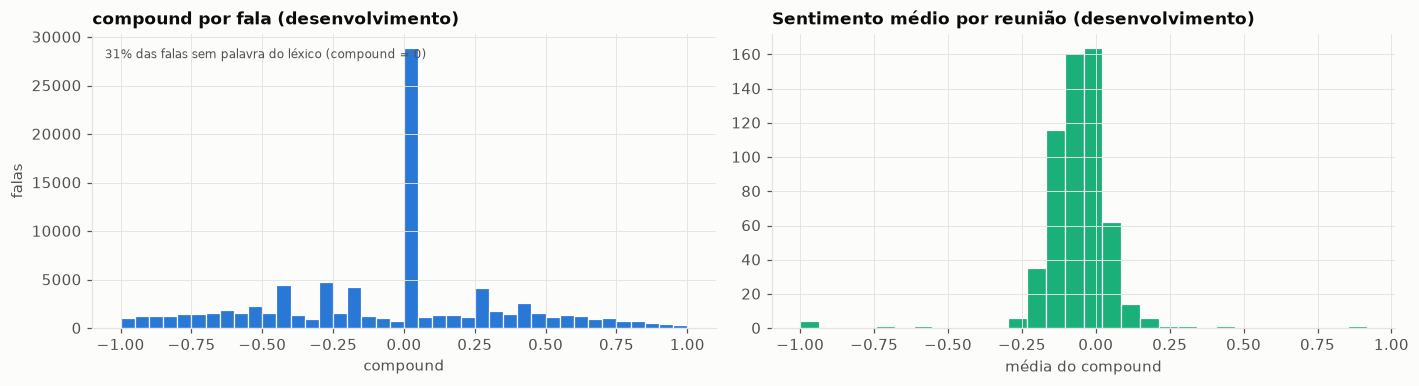

       sent_medio  sent_neg  sent_pos
count     574.000   574.000   574.000
mean       -0.061     0.254     0.185
std         0.126     0.115     0.096
min        -1.000     0.000     0.000
25%        -0.111     0.199     0.131
50%        -0.058     0.254     0.178
75%         0.000     0.308     0.231
max         0.917     1.000     1.000


In [16]:
# analisador de sentimento LeIA
from LeIA import SentimentIntensityAnalyzer
leia = SentimentIntensityAnalyzer()


# nota de sentimento de cada fala com 20 caracteres ou mais
def sentimento_falas(falas):
    return [leia.polarity_scores(t)['compound'] for _, t in falas if len(t) >= 20]


# separa as falas e calcula o sentimento de todas as reuniões
t0 = time.time()
FALAS = {i: transcritor(t) for i, t in df['TRANSCRICAO'].items()}
SENT = {i: sentimento_falas(f) for i, f in FALAS.items()}
print(f'sentimento de {sum(len(v) for v in SENT.values()):,} falas em {time.time() - t0:.0f} s')

# resumo por reunião: média, fração negativa e fração positiva
df['sent_medio'] = [np.mean(SENT[i]) if SENT[i] else 0 for i in df.index]
df['sent_neg'] = [np.mean(np.array(SENT[i]) <= -0.3) if SENT[i] else 0 for i in df.index]
df['sent_pos'] = [np.mean(np.array(SENT[i]) >= 0.3) if SENT[i] else 0 for i in df.index]

# histogramas do sentimento por fala e por reunião
todas = np.concatenate([SENT[i] for i in df.index[df.conjunto == 'desenvolvimento']])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].hist(todas, bins=40, color=COR[0], edgecolor='#fcfcfb', linewidth=0.8)
ax[0].set_title('compound por fala (desenvolvimento)'); ax[0].set_xlabel('compound'); ax[0].set_ylabel('falas')
ax[0].text(0.02, 0.95, f'{np.mean(todas == 0):.0%} das falas sem palavra do léxico (compound = 0)', transform=ax[0].transAxes, va='top', color=TINTA2, fontsize=8)
d = df[df.conjunto == 'desenvolvimento']
ax[1].hist(d['sent_medio'], bins=30, color=COR[2], edgecolor='#fcfcfb', linewidth=0.8)
ax[1].set_title('Sentimento médio por reunião (desenvolvimento)'); ax[1].set_xlabel('média do compound')
plt.tight_layout(); plt.show()
print(d[['sent_medio', 'sent_neg', 'sent_pos']].describe().round(3).to_string())

In [17]:
# as 5 falas mais negativas e as 5 mais positivas, para ver o que o léxico pega
exemplos = []
for i in df.index[df.conjunto == 'desenvolvimento'][:200]:
    for (f, t) in FALAS[i]:
        if 60 <= len(t) <= 220:
            exemplos.append((leia.polarity_scores(t)['compound'], t))
exemplos.sort()
print('Falas mais NEGATIVAS:')
for s, t in exemplos[:5]:
    print(f'  {s:+.2f}  {t}')
print('\nFalas mais POSITIVAS:')
for s, t in exemplos[-5:][::-1]:
    print(f'  {s:+.2f}  {t}')

Falas mais NEGATIVAS:
  -0.97  Dois usuários. É um show de bola. [PESSOA] adiante, então. Eu faço algumas perguntas, mas não vou falando igual. A ideia é entender também. Opa! Fugiu aqui a minha apresentação. Não,
  -0.96  eu cravo. Olha eu mandei mas aí ele me respondeu dizendo sim ou não e aí encerrei o processo. Aí eu começo a contar tempos. Olha mandei dentro do prazo certo mandei fora do prazo e por aí
  -0.96  Mas esse ano não teve aquela seca terrível aí pra cima, né? Nos rios, né? Os rios estão doendo mais ou não?
  -0.96  [LOCUTOR 1]: começar. Tchau, tchau. E aí E aí E aí E aí E aí E aí E aí [LOCAL], [LOCAL] que j'ai fait. Et [LOCAL] que j'ai fait. Merci. Merci.
  -0.95  Não, quem usa, quem é usuário, toquem! Na minha área é o inferno, pra dar manutenção no banco, cara! O banco do Proteus é o inferno! É uma delícia, tão estruturado!

Falas mais POSITIVAS:
  +0.97  meu amigo? Tudo bem com você, meu amigo? Tudo bem com você, meu amigo? Tudo bem com você, meu amigo?
  +0.95  bem 

O sentimento médio por reunião fica perto de zero e um pouco **negativo** (mediana −0,06; três quartos das reuniões ficam abaixo de 0). Isso não quer dizer que as reuniões sejam hostis. O léxico conta como negativas palavras muito comuns em conversa sobre sistema ("problema", "erro", "não"), mesmo em frases neutras ou positivas ("não tem problema"). E os extremos são ruído: repetições criadas pela diarização ("Tudo bem com você, meu amigo?" quatro vezes) e ironia que o léxico lê ao pé da letra ("O banco do Proteus é o inferno! É uma delícia"). Por isso o sentimento entra nos scores como **fração de falas muito negativas ou muito positivas**, convertida em percentil, e não pela média. E entra com peso menor que o do classificador.

## 3.2 Classificação de todos os trechos

O modelo escolhido classifica todos os trechos de todas as reuniões. Daí saem as taxas por reunião (que fração dos trechos caiu em cada categoria), que alimentam os scores.

In [18]:
# corta todas as reuniões em trechos e classifica cada um
t0 = time.time()
TRECHOS = {i: cortar_trechos(FALAS[i]) for i in df.index}
todos_textos = [t['trecho'] for i in df.index for t in TRECHOS[i]]
dono = np.repeat(df.index.values, [len(TRECHOS[i]) for i in df.index])
prev_todos = modelo.predict(todos_textos)
classes_modelo = list(modelo.classes_)
print(f'{len(todos_textos):,} trechos classificados em {time.time() - t0:.0f} s')
# fração de trechos de cada classe por reunião
contagem = pd.crosstab(dono, prev_todos)
for c in CLASSES:
    df['taxa_' + c] = (contagem.get(c, 0) / contagem.sum(axis=1)).reindex(df.index).fillna(0)
print((pd.Series(prev_todos).value_counts(normalize=True).round(3)).to_string())

90,343 trechos classificados em 25 s
nenhum          0.832
risco           0.088
proxima_acao    0.058
historico       0.023


Com o prior corrigido, a maior parte dos trechos sai como `nenhum`, perto da proporção do sorteio aleatório (68% nas reuniões pares). Mesmo assim, os scores usam as taxas de forma **relativa** (percentil dentro do desenvolvimento), e não como contagem de insights, porque a precisão por classe é baixa (seção 5).

## 3.3 Score de oportunidade e score de risco de churn

Os dois scores são **médias com pesos, feitas sobre percentis**. O percentil diz em que posição uma reunião fica quando comparada às reuniões de desenvolvimento, numa escala de 0 a 1: 0,8 quer dizer que o valor dela é maior que o de 80% dessas reuniões. Fazemos isso para poder somar coisas medidas em escalas diferentes. O score final vai de 0 a 100.

| Score | Componente | Peso | Por quê |
|---|---|---|---|
| **Risco de churn** | taxa de trechos `risco` (objeção ou risco) | 0,40 | sinal principal, vem do modelo validado |
| | menções de churn por 10 mil caracteres ("cancelar", "rescisão", "insatisfeito", "trocar de sistema", "suspender", "multa"...) | 0,25 | sinal direto de saída, raro e forte |
| | fração de falas negativas (LeIA) | 0,25 | tom da conversa |
| | concorrente do catálogo citado | 0,10 | cliente comparando alternativas |
| **Oportunidade** | taxa de trechos `proxima_acao` | 0,40 | sinal principal do modelo |
| | menções de compra por 10 mil caracteres ("proposta", "contratar", "orçamento", "cronograma", "assinatura"...) | 0,25 | avanço concreto do ciclo |
| | taxa de trechos `historico` (dores) | 0,20 | dor declarada é demanda a resolver |
| | fração de falas positivas (LeIA) | 0,15 | receptividade da conversa |

Os pesos são uma decisão de negócio, não saíram de um ajuste estatístico. Com só 310 NPS e nenhum dado real de churn, ajustar os pesos por regressão faria o modelo decorar os dados em vez de aprender. Eles são **testados** contra o NPS no holdout (seção 5). As faixas são: baixo abaixo de 40, médio de 40 até antes de 70 e alto de 70 para cima. São as mesmas três faixas do `status_risco_atual` do analista antigo.

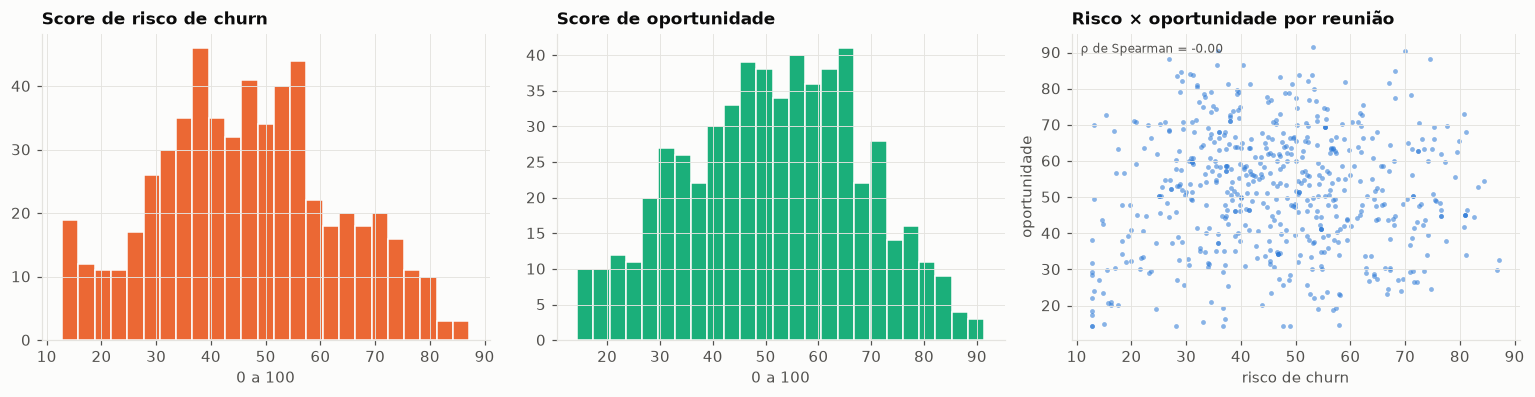

oportunidade  alto  baixo  médio
risco                           
alto             4     14     42
baixo           39     62    114
médio           39     72    188


In [19]:
# palavras que indicam saída do cliente e palavras que indicam compra
LEX_CHURN = r'cancel|rescis|rescind|insatisf|descontent|trocar de sistema|trocar o sistema|sair d[ao] totvs|desist|suspend|multa|frustra|reclama|não funciona|travou|trava'
LEX_COMPRA = r'proposta|contrat|orçamento|cronograma|assinatura|assinar|fechar|fechamento|implanta|kickoff|próximos passos|próximo passo|aprova'


# quantas vezes as palavras aparecem a cada 10 mil caracteres
def por_10mil(texto, lex):
    return len(re.findall(lex, texto.lower())) / max(len(texto), 1) * 1e4


# componentes dos scores para todas as reuniões
df['churn_10k'] = [por_10mil(t, LEX_CHURN) for t in df['TRANSCRICAO']]
df['compra_10k'] = [por_10mil(t, LEX_COMPRA) for t in df['TRANSCRICAO']]
df['concorrente'] = [int(bool(citados(t, PADROES_CONCORRENTE))) for t in df['TRANSCRICAO']]

# peso de cada componente nos dois scores
PESOS_RISCO = {'taxa_risco': 0.40, 'churn_10k': 0.25, 'sent_neg': 0.25, 'concorrente': 0.10}
PESOS_OPORT = {'taxa_proxima_acao': 0.40, 'compra_10k': 0.25, 'taxa_historico': 0.20, 'sent_pos': 0.15}
REF = df[df.conjunto == 'desenvolvimento']          # referência dos percentis: só desenvolvimento


# posição do valor entre as reuniões de desenvolvimento (0 a 1)
def percentil(col, valores):
    ref = np.sort(REF[col].values)
    return np.searchsorted(ref, valores, side='right') / len(ref)


# soma com pesos dos percentis, de 0 a 100
def score(linha_ou_df, pesos):
    return 100 * sum(p * (percentil(c, linha_ou_df[c]) if c != 'concorrente' else linha_ou_df[c]) for c, p in pesos.items())


# faixas baixo, médio e alto
def faixa(s):
    return 'alto' if s >= 70 else ('médio' if s >= 40 else 'baixo')


# calcula os dois scores
df['score_risco'] = score(df, PESOS_RISCO).round(1)
df['score_oportunidade'] = score(df, PESOS_OPORT).round(1)

# histogramas e cruzamento dos dois scores
d = df[df.conjunto == 'desenvolvimento']
fig, ax = plt.subplots(1, 3, figsize=(14, 3.7))
ax[0].hist(d['score_risco'], bins=25, color=COR[1], edgecolor='#fcfcfb'); ax[0].set_title('Score de risco de churn'); ax[0].set_xlabel('0 a 100')
ax[1].hist(d['score_oportunidade'], bins=25, color=COR[2], edgecolor='#fcfcfb'); ax[1].set_title('Score de oportunidade'); ax[1].set_xlabel('0 a 100')
ax[2].scatter(d['score_risco'], d['score_oportunidade'], s=10, color=COR[0], alpha=0.55, linewidths=0)
ax[2].set_xlabel('risco de churn'); ax[2].set_ylabel('oportunidade'); ax[2].set_title('Risco × oportunidade por reunião')
ax[2].text(0.02, 0.97, f"ρ de Spearman = {d['score_risco'].corr(d['score_oportunidade'], method='spearman'):.2f}", transform=ax[2].transAxes, va='top', color=TINTA2, fontsize=8)
plt.tight_layout(); plt.show()
print(pd.crosstab(d['score_risco'].map(faixa), d['score_oportunidade'].map(faixa), rownames=['risco'], colnames=['oportunidade']).to_string())

## 3.4 Termos e indicadores por tópico

In [20]:
# tema de cada reunião da base inteira
theta_all = lda.transform(vet_topicos.transform(df['TRANSCRICAO']))
df['topico'] = theta_all.argmax(axis=1)
df['tema'] = df['topico'].map(NOMES_TOPICO)
d = df[df.conjunto == 'desenvolvimento']
# médias dos indicadores por tema
por_tema = d.groupby('tema').agg(reunioes=('ID_MEETING', 'size'), risco=('score_risco', 'mean'),
                                 oportunidade=('score_oportunidade', 'mean'), sentimento=('sent_medio', 'mean'),
                                 NPS=('NOTA_NPS', 'mean'), n_NPS=('NOTA_NPS', 'count')).round(2)
por_tema['termos principais'] = [', '.join(termos_topico[[k for k, v in NOMES_TOPICO.items() if v == tema][0]][:8]) for tema in por_tema.index]
display(por_tema.sort_values('risco', ascending=False))

# palavras que mais puxam para cada classe. O modelo final usa pedaços de letras, difíceis de ler,
# então aqui treinamos um NB de palavras só para mostrar quais termos pesam mais em cada classe
leitura = make_pipeline(tfidf_palavras(), MultinomialNB(alpha=0.3)).fit(X_tr, y_tr)
vet_l, nb_l = leitura.steps[0][1], leitura.steps[-1][1]
nomes_feat = np.array(vet_l.get_feature_names_out())
base_nenhum = nb_l.feature_log_prob_[list(nb_l.classes_).index('nenhum')]
for c in ['historico', 'risco', 'proxima_acao']:
    razao = nb_l.feature_log_prob_[list(nb_l.classes_).index(c)] - base_nenhum
    termos = [t for t in nomes_feat[np.argsort(razao)[::-1]] if t not in PARADAS][:15]
    print(f'{c:13s}:', ', '.join(termos))

,reunioes,risco,oportunidade,sentimento,NPS,n_NPS,termos principais
tema,,,,,,,
Projeto e implantação,227,52.63,50.71,-0.08,7.92,71,"escopo, proteus, feira, suporte, ambiente, resolver, teste, fluig"
Financeiro e back office,104,45.19,56.11,-0.05,8.67,6,"saúde, office, boleto, banco, vender, contas, back, venda"
"Fiscal, compras e estoque",78,45.07,49.06,-0.08,7.91,22,"nota, estoque, proteus, ordem, compra, fiscal, produção, entrada"
Saúde,41,41.31,52.68,-0.03,7.00,15,"paciente, médico, prontuário, agendamento, hospital, clínica, convênio, exames"
"Vendas, CRM e marketing",62,40.20,49.36,-0.03,8.00,17,"crm, venda, vendedor, vendas, marketing, orçamento, oportunidade, conversas"
RH e gestão de pessoas,62,39.81,52.59,-0.04,8.05,21,"colaborador, folha, colaboradores, gestor, documento, avaliação, treinamento, aplicativo"


historico    : usa, manter, manual, leitos, nota, casa, chama, gestor, queriam, financeiro, atendimento, tento, relógio, estabelecimento, liberação
risco        : sustentação, assunto, entendo, negócio, problema, telefone, propor, cancelar, opção, pediu, compras, solicitações, reuniões, junto, ant
proxima_acao : poder, wms, totos, contrato, volume, sair, teve, interesse, proximidade, produto, passo, próximo, apresentar, certeza, empresas


**Leitura por tema.** As reuniões de **Projeto e implantação** (o tema mais comum, 227 reuniões de desenvolvimento) têm o maior score médio de risco, e as de **RH e gestão de pessoas**, o menor. Isso não quer dizer que cliente em implantação esteja mais perto de cancelar. Reunião de implantação fala, por natureza, de prazo, chamado, erro e escopo, que são justamente os sinais que o modelo e o léxico ligam a risco. O score mede **atrito na conversa**, e em alguns temas o atrito é esperado. Na prática, o score de risco deve ser comparado **dentro do mesmo tema** (ou com o histórico do próprio cliente, como faz o analista), e não entre temas. **Financeiro e back office** tem o maior score médio de oportunidade (56). Os termos do tópico (boleto, banco, contas, vender) sugerem conversas sobre contratar módulos financeiros, em que proposta e contratação aparecem bastante. Mas essa leitura é nossa: a gente não conferiu trecho por trecho. O NPS médio por tema varia pouco e tem poucas notas por grupo (6 em Financeiro e back office), então não dá para comparar.

Os termos que mais separam cada classe na amostra rotulada (última saída acima) mostram o que um classificador aprende com 60 trechos. "WMS", "contrato", "interesse", "próximo passo" e "apresentar" puxam para `proxima_acao`; "sustentação", "problema", "cancelar" e "solicitações" puxam para `risco`; "manter", "manual" e "relógio" (controle de ponto) puxam para `historico`. Também aparecem palavras que não têm nada a ver com a classe ("telefone", "casa", "teve"), sinal de que parte do que o modelo aprendeu é coincidência da amostra. São pistas razoáveis, mas poucas e rasas, e isso explica a dificuldade com insights ditos de outro jeito.

<a id="4"></a>
# 4. Protótipo

## 4.1 Função `analisar_transcricao`

A função recebe o texto de uma transcrição nova (no formato `[LOCUTOR n]: fala`) e roda os quatro passos da versão sequencial, um depois do outro, como fazia o `SequentialAgent`. Ela devolve **produto, tema, sentimento, risco de churn, oportunidade, termos, recomendação e o registro de CRM em JSON**, no formato do `estruturador_crm` de `e4d6257` (sem os campos de confiança). Se a gente passar o histórico do cliente, o analista usa esse histórico na comparação.

In [21]:
# palavras que fazem um trecho de risco virar objeção
PISTA_OBJECAO = r'caro|preço|valor|custo|desconto|orçamento|prazo|proposta|contrato|cláusula|não está clar|não sei se'
# TF-IDF para listar os termos que mais marcam a reunião
vet_termos = TfidfVectorizer(preprocessor=texto_limpo, token_pattern=r'(?u)\b[a-zà-ú]{4,}\b', stop_words=list(PARADAS),
                             min_df=3, max_df=0.5).fit(REF['TRANSCRICAO'])
# recomendação para cada combinação de nível de risco e de oportunidade
RECOMENDACOES = {
    ('alto', 'alto'): 'Cliente engajado mas com atrito: tratar as objeções listadas antes de avançar a proposta; envolver o gestor da conta em até 48 h.',
    ('alto', 'médio'): 'Priorizar retenção: acionar Customer Success em até 48 h com as evidências de risco e um plano de ação para cada ponto.',
    ('alto', 'baixo'): 'Alerta de churn: escalar para o gestor da conta, agendar reunião de alinhamento e revisar SLA de suporte e condições comerciais.',
    ('médio', 'alto'): 'Avançar: enviar proposta ou agendar demonstração do produto citado, respondendo às objeções na própria proposta.',
    ('baixo', 'alto'): 'Oportunidade quente: enviar proposta em até 24 h e marcar o próximo passo com data.',
    ('médio', 'médio'): 'Acompanhar: registrar as dores no CRM e voltar ao cliente com casos de uso do produto citado.',
}


def recomendacao(nivel_risco, nivel_oport):
    return RECOMENDACOES.get((nivel_risco, nivel_oport), 'Nutrir: manter contato periódico; não há sinal forte de risco nem de compra nesta reunião.')


def extrator_de_insights(falas, max_por_tipo=3):
    """Passo 2: trechos classificados, com concorrente e produto só se escritos no próprio trecho."""
    trechos = cortar_trechos(falas)
    if not trechos:
        return [], trechos
    textos = [t['trecho'] for t in trechos]
    prev = modelo.predict(textos)
    marg = margem(textos)
    insights = []
    for c in ['risco', 'proxima_acao', 'historico']:
        k = classes_modelo.index(c)
        idx = [i for i in np.argsort(marg[:, k])[::-1] if prev[i] == c][:max_por_tipo]
        for i in idx:
            ev = re.sub(r'\[LOCUTOR \d+\]:\s*', '', textos[i]).replace('\n', ' ')
            tipo = {'historico': 'dor', 'proxima_acao': 'oportunidade'}.get(c) or \
                ('objecao' if re.search(PISTA_OBJECAO, ev.lower()) else 'risco')
            insights.append({'tipo_insight': tipo, 'insight': None, 'evidencia': ev,
                             'falante': trechos[i]['falante'], 'timestamp_aproximado': None,
                             'concorrente_mencionado': (citados(ev, PADROES_CONCORRENTE) or [None])[0],
                             'produto_totvs_mencionado': (citados(ev, PADROES_PRODUTO) or [None])[0],
                             '_margem': float(marg[i, k])})
    return insights, trechos


def analista_de_historico_e_risco(cliente, indicadores, historico):
    """Passo 3: status de risco atual, mudança desde a última reunião e temas recorrentes."""
    nivel = faixa(indicadores['score_risco'])
    if historico is None or len(historico) == 0:
        mudanca, recorrentes = 'sem reunião anterior deste cliente', []
    else:
        anterior = historico.sort_values('DT_MEETING').iloc[-1]
        delta = indicadores['score_risco'] - anterior['score_risco']
        mudanca = (f"piorou ({anterior['score_risco']:.0f} → {indicadores['score_risco']:.0f})" if delta >= 10 else
                   f"melhorou ({anterior['score_risco']:.0f} → {indicadores['score_risco']:.0f})" if delta <= -10 else
                   f"manteve-se ({anterior['score_risco']:.0f} → {indicadores['score_risco']:.0f})")
        temas = list(historico.sort_values('DT_MEETING')['tema'].iloc[-3:]) + [indicadores['tema']]
        recorrentes = [t for t, n in Counter(temas).items() if n >= 2]
    return {'cliente': cliente, 'status_risco_atual': nivel.replace('é', 'e'),
            'mudanca_desde_ultima_reuniao': mudanca, 'insights_recorrentes': recorrentes}


# regra fixa do estruturador antigo: tipo do insight vira categoria do CRM
CATEGORIA_CRM = {'dor': 'historico', 'objecao': 'risco', 'risco': 'risco', 'oportunidade': 'proxima_acao'}


def estruturador_crm(cliente, insights, analise):
    """Passo 4: JSON do CRM com a regra fixa de categoria_crm de e4d6257."""
    return {'insights': [{'cliente': cliente, 'tipo_insight': i['tipo_insight'],
                          'categoria_crm': CATEGORIA_CRM[i['tipo_insight']],
                          'resumo': (i['evidencia'][:140] + '…') if len(i['evidencia']) > 140 else i['evidencia'],
                          'evidencia': i['evidencia'], 'timestamp_aproximado': i['timestamp_aproximado'],
                          'falante': i['falante'], 'concorrente_mencionado': i['concorrente_mencionado'],
                          'produto_totvs_mencionado': i['produto_totvs_mencionado']} for i in insights],
            'status_risco_atual': analise}


# protótipo: roda os quatro passos em fila e mede o tempo de cada um
def analisar_transcricao(transcricao, cliente='cliente_novo', historico=None, medir=False):
    tempos = {}
    # passos 1 e 2: falas e insights
    t = time.perf_counter(); falas = transcritor(mascarar(transcricao)); tempos['transcritor'] = time.perf_counter() - t
    t = time.perf_counter(); insights, trechos = extrator_de_insights(falas); tempos['extrator_de_insights'] = time.perf_counter() - t

    # passo 3: indicadores, scores, tema e comparação com o histórico
    t = time.perf_counter()
    texto = '\n'.join(f for _, f in falas)
    sent = sentimento_falas(falas)
    prev = modelo.predict([x['trecho'] for x in trechos]) if trechos else np.array([])
    ind = pd.DataFrame([{
        **{'taxa_' + c: float(np.mean(prev == c)) if len(prev) else 0.0 for c in CLASSES},
        'sent_medio': float(np.mean(sent)) if sent else 0.0,
        'sent_neg': float(np.mean(np.array(sent) <= -0.3)) if sent else 0.0,
        'sent_pos': float(np.mean(np.array(sent) >= 0.3)) if sent else 0.0,
        'churn_10k': por_10mil(texto, LEX_CHURN), 'compra_10k': por_10mil(texto, LEX_COMPRA),
        'concorrente': int(bool(citados(texto, PADROES_CONCORRENTE))),
    }])
    ind['score_risco'] = score(ind, PESOS_RISCO).round(1)
    ind['score_oportunidade'] = score(ind, PESOS_OPORT).round(1)
    ind = ind.iloc[0].to_dict()
    ind['tema'] = NOMES_TOPICO[int(lda.transform(vet_topicos.transform([transcricao])).argmax())]
    analise = analista_de_historico_e_risco(cliente, ind, historico)
    tempos['analista_de_historico_e_risco'] = time.perf_counter() - t

    # passo 4: registro de CRM
    t = time.perf_counter(); crm = estruturador_crm(cliente, insights, analise); tempos['estruturador_crm'] = time.perf_counter() - t

    # monta a saída final do protótipo
    produtos = Counter(citados(texto, PADROES_PRODUTO))
    tfidf = vet_termos.transform([texto]).toarray()[0]
    termos = list(np.array(vet_termos.get_feature_names_out())[np.argsort(tfidf)[::-1][:10]])
    nr, no = faixa(ind['score_risco']), faixa(ind['score_oportunidade'])
    saida = {
        'produto': produtos.most_common(1)[0][0] if produtos else 'não identificado no catálogo e4d6257',
        'produtos_citados': dict(produtos),
        'tema': ind['tema'],
        'sentimento': {'medio': round(ind['sent_medio'], 3), 'falas_negativas': round(ind['sent_neg'], 3),
                       'falas_positivas': round(ind['sent_pos'], 3),
                       'rotulo': 'positivo' if ind['sent_medio'] >= 0.15 else ('negativo' if ind['sent_medio'] <= 0 else 'neutro')},
        'risco_churn': {'score': ind['score_risco'], 'nivel': nr},
        'oportunidade': {'score': ind['score_oportunidade'], 'nivel': no},
        'termos': termos,
        'recomendacao': recomendacao(nr, no),
        'registro_crm': crm,
    }
    return (saida, tempos) if medir else saida

## 4.2 Demonstração com uma transcrição do holdout e linha do tempo medida

Escolhemos uma reunião de índice ímpar (que o desenvolvimento nunca viu) de um cliente que já tem outras reuniões na base, para o analista de histórico ter com o que comparar. O histórico também vem só do holdout.

In [22]:
# escolhe uma reunião do holdout de um cliente com 3 reuniões ou mais
hold = df[df.conjunto == 'holdout']
repetidos = hold.groupby('CODT').filter(lambda g: len(g) >= 3)
alvo = repetidos.sort_values('DT_MEETING').groupby('CODT').tail(1).sort_values('N_CARACTERES').iloc[len(repetidos.groupby('CODT')) // 2]
historico_alvo = hold[(hold.CODT == alvo.CODT) & (hold.DT_MEETING < alvo.DT_MEETING)]
print(f"reunião índice {alvo.indice} · segmento {alvo.NOME_SEGMENTO} · {alvo.DURACAO_MIN:.0f} min · {len(historico_alvo)} reuniões anteriores do cliente no holdout")

# roda o protótipo e mostra tudo menos o registro de CRM
resultado, tempos = analisar_transcricao(alvo.TRANSCRICAO, cliente=f'cliente_{alvo.CODT}', historico=historico_alvo, medir=True)
vista = {k: v for k, v in resultado.items() if k != 'registro_crm'}
print(json.dumps(vista, ensure_ascii=False, indent=2))

reunião índice 329 · segmento VAREJO · 57 min · 2 reuniões anteriores do cliente no holdout
{
  "produto": "não identificado no catálogo e4d6257",
  "produtos_citados": {},
  "tema": "Projeto e implantação",
  "sentimento": {
    "medio": -0.078,
    "falas_negativas": 0.259,
    "falas_positivas": 0.134,
    "rotulo": "negativo"
  },
  "risco_churn": {
    "score": 48.6,
    "nivel": "médio"
  },
  "oportunidade": {
    "score": 68.0,
    "nivel": "médio"
  },
  "termos": [
    "continental",
    "será",
    "estrutura",
    "teremos",
    "viés",
    "marca",
    "instalação",
    "instância",
    "conheço",
    "aproveitar"
  ],
  "recomendacao": "Acompanhar: registrar as dores no CRM e voltar ao cliente com casos de uso do produto citado."
}


In [23]:
# os 4 primeiros insights do registro de CRM
crm = resultado['registro_crm']
print(json.dumps({'insights': crm['insights'][:4], 'status_risco_atual': crm['status_risco_atual']}, ensure_ascii=False, indent=2))
print(f"... {len(crm['insights'])} insights no total")

{
  "insights": [
    {
      "cliente": "cliente_TEXVHQ",
      "tipo_insight": "objecao",
      "categoria_crm": "risco",
      "resumo": "Entendi. Entendi. Eu acho que para o dia, assim, acredito que, não sei se vocês também têm mais dúvidas, mas eu acredito que sanei as minhas…",
      "evidencia": "Entendi. Entendi. Eu acho que para o dia, assim, acredito que, não sei se vocês também têm mais dúvidas, mas eu acredito que sanei as minhas. Acredito que ali para o dia 16, inclusive eu convidaria o [PESSOA] também, que é o diretor de [EMPRESA] aqui, para participar. E aí nós até nos reuniremos com ele antes, por isso que eu pedi para gravar ali, para que a gente possa debater com ele alguns pontos aqui. mas para o dia 16, de novo, não sei se será possível, mas",
      "timestamp_aproximado": null,
      "falante": "LOCUTOR 18",
      "concorrente_mencionado": null,
      "produto_totvs_mencionado": null
    },
    {
      "cliente": "cliente_TEXVHQ",
      "tipo_insight": "risco",
   

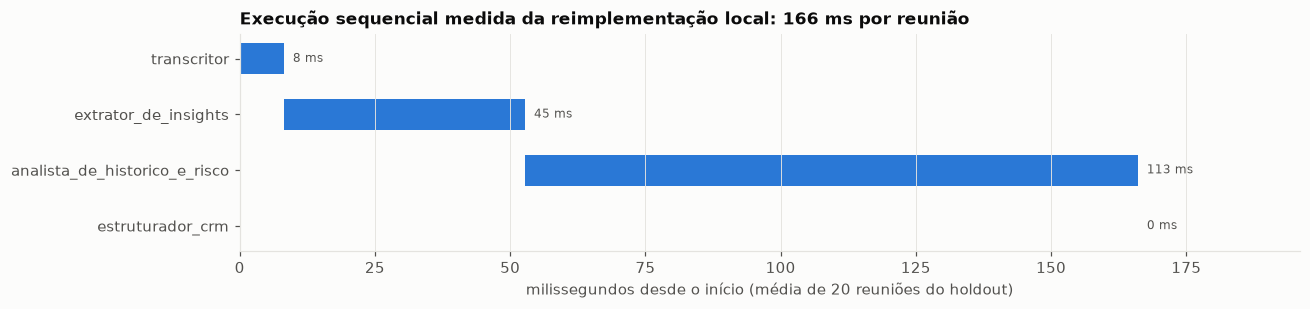

In [24]:
# linha do tempo medida: média de 20 reuniões do holdout, com os passos em fila
amostra_tempo = hold.sample(20, random_state=SEMENTE)
medidas = pd.DataFrame([analisar_transcricao(t, medir=True)[1] for t in amostra_tempo['TRANSCRICAO']])
media = medidas.mean() * 1000
fig, ax = plt.subplots(figsize=(12, 2.9))
inicio = 0
for i, (passo, ms) in enumerate(media.items()):
    ax.barh(len(media) - 1 - i, ms, left=inicio, color=COR[0], height=0.55)
    ax.text(inicio + ms + media.sum() * 0.01, len(media) - 1 - i, f'{ms:.0f} ms', va='center', fontsize=8, color=TINTA2)
    inicio += ms
ax.set_yticks(range(len(media))); ax.set_yticklabels(list(media.index)[::-1]); ax.grid(axis='y', visible=False)
ax.set_xlabel('milissegundos desde o início (média de 20 reuniões do holdout)')
ax.set_title(f'Execução sequencial medida da reimplementação local: {media.sum():.0f} ms por reunião')
ax.set_xlim(0, media.sum() * 1.18)
plt.tight_layout(); plt.show()

No computador, a reunião inteira é processada em menos de um segundo, e o passo mais demorado é o analista, que calcula o sentimento de todas as falas e os indicadores. Na versão original, cada passo era uma chamada ao Gemini com a transcrição ou os insights no prompt. O tempo total era a soma das quatro respostas, mais as esperas quando a chamada precisava ser repetida: o `RETRY_PIPELINE` daquela versão aceitava esperar até 67 s por chamada quando o serviço respondia 429 (excesso de pedidos). O formato da linha do tempo é o mesmo; o que muda é a escala.

<a id="5"></a>
# 5. Validação com novas transcrições (holdout de índice ímpar)

Fizemos três verificações, todas com reuniões que não participaram de nenhum ajuste:

1. **Trechos rotulados do holdout** (40): o classificador treinado nos 60 de desenvolvimento.
2. **Distribuição real**: o classificador em trechos aleatórios do holdout, para ver o efeito da proporção de classes.
3. **Scores contra o NPS**: as 573 reuniões do holdout passam pelo protótipo, e comparamos o score de risco com o NPS das que têm pesquisa.

## 5.1 Trechos rotulados do holdout

,acurácia,precisão macro,recall macro,F1 macro
modelo,,,,
TF-IDF + Naive Bayes,0.325,0.340,0.314,0.318
TF-IDF + SVM linear,0.275,0.278,0.276,0.273
Regra de palavras-pista,0.450,0.471,0.455,0.449
TF-IDF + Naive Bayes com prior corrigido (final),0.325,0.261,0.279,0.241


=== modelo final (TF-IDF + Naive Bayes, prior corrigido) no holdout balanceado ===
              precision    recall  f1-score   support

   historico       0.00      0.00      0.00         8
       risco       0.40      0.22      0.29         9
proxima_acao       0.33      0.20      0.25        10
      nenhum       0.31      0.69      0.43        13

    accuracy                           0.33        40
   macro avg       0.26      0.28      0.24        40
weighted avg       0.27      0.33      0.27        40



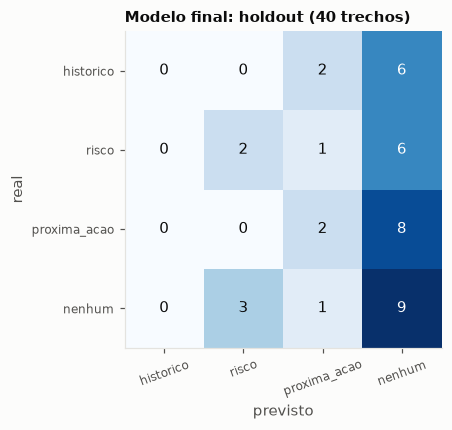

In [25]:
# treina cada modelo nos 60 trechos e testa nos 40 do holdout
X_te, y_te = teste['trecho'].values, teste['categoria_crm'].values
linhas_h = []
for nome, fabrica in list(MODELOS.items()) + [('Regra de palavras-pista', lambda: RegraPistas())]:
    m = fabrica().fit(X_tr, y_tr)
    p = m.predict(X_te)
    pr, rc, f1, _ = precision_recall_fscore_support(y_te, p, labels=CLASSES, average='macro', zero_division=0)
    linhas_h.append({'modelo': nome, 'acurácia': accuracy_score(y_te, p), 'precisão macro': pr, 'recall macro': rc, 'F1 macro': f1})
# modelo final, com o prior corrigido
prev_te = modelo.predict(X_te)
pr, rc, f1, _ = precision_recall_fscore_support(y_te, prev_te, labels=CLASSES, average='macro', zero_division=0)
linhas_h.append({'modelo': ESCOLHIDO + ' com prior corrigido (final)', 'acurácia': accuracy_score(y_te, prev_te),
                 'precisão macro': pr, 'recall macro': rc, 'F1 macro': f1})
display(pd.DataFrame(linhas_h).set_index('modelo').round(3))
print(f'=== modelo final ({ESCOLHIDO}, prior corrigido) no holdout balanceado ===')
print(classification_report(y_te, prev_te, labels=CLASSES, digits=2, zero_division=0))

# matriz de confusão do modelo final
cm = confusion_matrix(y_te, prev_te, labels=CLASSES)
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm, cmap='Blues'); ax.grid(False)
ax.set_xticks(range(4)); ax.set_xticklabels(CLASSES, rotation=20, fontsize=8); ax.set_yticks(range(4)); ax.set_yticklabels(CLASSES, fontsize=8)
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() * 0.55 else TINTA)
ax.set_xlabel('previsto'); ax.set_ylabel('real'); ax.set_title('Modelo final: holdout (40 trechos)', fontsize=10)
plt.tight_layout(); plt.show()

## 5.2 Proporção real de classes

No sorteio aleatório inicial do holdout (antes de reforçar a amostra por classe), a proporção de trechos sem insight é bem maior. Aqui medimos quantos trechos aleatórios de reuniões do holdout o modelo marca como insight e se ele acerta quando marca.

In [26]:
# trechos aleatórios do holdout, com a proporção real de classes
sorteio_h = sorteio[sorteio.conjunto == 'holdout'].copy()
sem_prior = MODELOS[ESCOLHIDO]().fit(X_tr, y_tr)
print('proporção real no sorteio aleatório do holdout (40 trechos):', sorteio_h['real'].value_counts(normalize=True).round(2).to_dict())
# compara a regra, o NB sem correção e o modelo final
linhas_r = []
for nome, m in [('Regra de palavras-pista', RegraPistas()), ('Naive Bayes, prior da amostra balanceada', sem_prior),
                ('Naive Bayes, prior corrigido (final)', modelo)]:
    prev = m.predict(sorteio_h['trecho'].values)
    pr, rc, f1, _ = precision_recall_fscore_support(sorteio_h['real'] != 'nenhum', prev != 'nenhum', average='binary')
    linhas_r.append({'modelo': nome, '% previsto como nenhum': np.mean(prev == 'nenhum'), 'precisão (insight)': pr,
                     'recall (insight)': rc, 'F1 (insight × nenhum)': f1,
                     'F1 macro 4 classes': f1_score(sorteio_h['real'], prev, average='macro', labels=CLASSES, zero_division=0)})
display(pd.DataFrame(linhas_r).set_index('modelo').round(2))

proporção real no sorteio aleatório do holdout (40 trechos): {'nenhum': 0.7, 'historico': 0.1, 'risco': 0.1, 'proxima_acao': 0.1}


,% previsto como nenhum,precisão (insight),recall (insight),F1 (insight × nenhum),F1 macro 4 classes
modelo,,,,,
Regra de palavras-pista,0.60,0.38,0.50,0.43,0.35
"Naive Bayes, prior da amostra balanceada",0.28,0.34,0.83,0.49,0.26
"Naive Bayes, prior corrigido (final)",0.80,0.50,0.33,0.40,0.39


**O que 5.1 e 5.2 mostram.** Na amostra balanceada do holdout, o modelo final tem F1 macro de 0,24, abaixo do próprio NB sem correção (0,32). Esse é o preço da correção do prior: o modelo fica cauteloso, diz `nenhum` sempre que a evidência é fraca e perde recall nas classes de insight (`historico` não é reconhecida nenhuma vez). Mas na distribuição que o protótipo encontra de verdade (5.2, 70% de `nenhum`), a troca vale a pena: a fração prevista como `nenhum` passa de 28% para 80%, a precisão de "este trecho tem insight" sobe de 0,34 para 0,50 e o F1 macro das quatro classes sobe de 0,26 para 0,39. Para um CRM, isso quer dizer gravar **menos insights, com metade deles certos**, em vez de três vezes mais insights com só um terço certos.

São 40 trechos em cada avaliação, então diferenças de 0,05 a 0,10 podem ser só efeito do sorteio. O que dá para afirmar é a direção: com estes rótulos, nenhum modelo local passa de F1 0,4 por trecho, e a correção do prior troca recall por precisão, como a gente esperava.

## 5.3 Scores contra o NPS das reuniões do holdout

O NPS é a nota que o cliente dá na pesquisa da TOTVS. Ele não é um rótulo de churn, e a data da pesquisa nem sempre fica perto da reunião. Mesmo assim, é o único sinal de fora que temos: se o score de risco capta algo real, os **detratores (NPS ≤ 6)** deveriam ter score de risco mais alto.

Para medir isso usamos a **AUC**: é a chance de um detrator sorteado ter score maior que um não detrator sorteado. AUC de 0,5 é igual a tirar no cara ou coroa; 1 seria acertar sempre. O intervalo de confiança da AUC sai do *bootstrap*: sorteamos a amostra de novo, com reposição, muitas vezes e vemos quanto o resultado varia. Também medimos a correlação de Spearman com a nota, que mostra se as duas coisas sobem e descem juntas (vai de −1 a +1).

reuniões do holdout com NPS: 158 · detratores: 24


,AUC detrator,IC 95%,Spearman com NPS,p-valor
indicador,,,,
score de risco de churn,0.424,0.30 a 0.54,-0.011,0.888
só a taxa de trechos de risco,0.444,0.33 a 0.56,0.009,0.908
só o léxico de churn,0.536,0.42 a 0.65,-0.032,0.687
só a fração de falas negativas,0.422,0.31 a 0.53,0.015,0.852
sentimento médio (invertido),0.415,0.30 a 0.53,-0.022,0.788
score de oportunidade (invertido),0.375,0.26 a 0.49,0.126,0.114


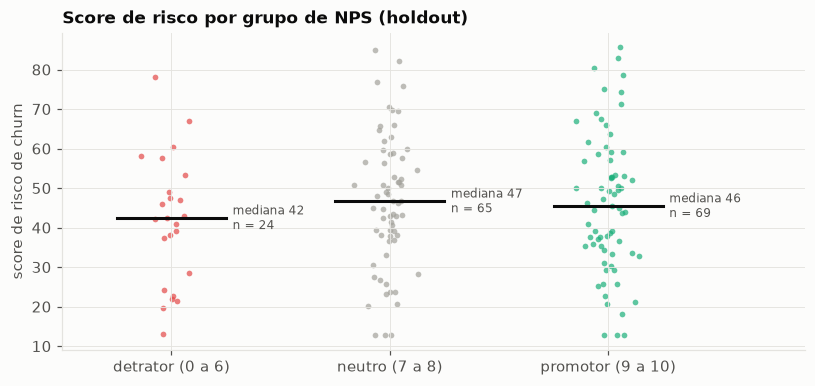

In [27]:
# testes estatísticos
from scipy.stats import spearmanr, mannwhitneyu


# AUC: chance de um detrator ter score maior que um não detrator
def auc(pos, neg):
    u = mannwhitneyu(pos, neg, alternative='two-sided').statistic
    return u / (len(pos) * len(neg))


# intervalo de confiança da AUC por bootstrap (sorteios com reposição)
def auc_ic(score_col, base, n=2000):
    rng = np.random.default_rng(SEMENTE)
    det = base['NOTA_NPS'] <= 6
    s, y = base[score_col].values, det.values
    boots = []
    for _ in range(n):
        i = rng.integers(0, len(s), len(s))
        if y[i].all() or (~y[i]).all():
            continue
        boots.append(auc(s[i][y[i]], s[i][~y[i]]))
    return auc(s[y], s[~y]), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


# reuniões do holdout com NPS; sentimento e oportunidade invertidos para ler no mesmo sentido do risco
h_nps = df[(df.conjunto == 'holdout') & df['NOTA_NPS'].notna()].copy()
h_nps['menos_sent_medio'] = -h_nps['sent_medio']
h_nps['menos_oportunidade'] = -h_nps['score_oportunidade']
print(f"reuniões do holdout com NPS: {len(h_nps)} · detratores: {int((h_nps['NOTA_NPS'] <= 6).sum())}")
# AUC e Spearman de cada indicador
val = []
for col, nome in [('score_risco', 'score de risco de churn'), ('taxa_risco', 'só a taxa de trechos de risco'),
                  ('churn_10k', 'só o léxico de churn'), ('sent_neg', 'só a fração de falas negativas'),
                  ('menos_sent_medio', 'sentimento médio (invertido)'), ('menos_oportunidade', 'score de oportunidade (invertido)')]:
    a, lo, hi = auc_ic(col, h_nps)
    rho, p = spearmanr(h_nps[col], h_nps['NOTA_NPS'])
    val.append({'indicador': nome, 'AUC detrator': a, 'IC 95%': f'{lo:.2f} a {hi:.2f}', 'Spearman com NPS': rho, 'p-valor': p})
display(pd.DataFrame(val).set_index('indicador').round(3))

# score de risco por grupo de NPS
fig, ax = plt.subplots(figsize=(7.5, 3.6))
grupos = [('detrator (0 a 6)', h_nps['NOTA_NPS'] <= 6, COR[7]), ('neutro (7 a 8)', h_nps['NOTA_NPS'].between(7, 8), '#a3a29b'), ('promotor (9 a 10)', h_nps['NOTA_NPS'] >= 9, COR[2])]
for k, (nome, m, cor) in enumerate(grupos):
    v = h_nps.loc[m, 'score_risco']
    ax.scatter(np.random.default_rng(k).normal(k, 0.06, len(v)), v, s=14, color=cor, alpha=0.7, linewidths=0)
    ax.plot([k - 0.25, k + 0.25], [v.median()] * 2, color=TINTA, lw=2)
    ax.text(k + 0.28, v.median(), f'mediana {v.median():.0f}\nn = {len(v)}', va='center', fontsize=8, color=TINTA2)
ax.set_xticks(range(3)); ax.set_xticklabels([g[0] for g in grupos]); ax.set_ylabel('score de risco de churn')
ax.set_title('Score de risco por grupo de NPS (holdout)'); ax.set_xlim(-0.5, 2.9)
plt.tight_layout(); plt.show()

**O score de risco não separa detratores de não detratores no holdout.** A AUC de 0,42 tem intervalo de confiança de 0,30 a 0,54, que inclui 0,5 (acaso), e a correlação de Spearman com a nota fica praticamente em zero. Nenhum componente sozinho vai melhor: o léxico de churn chega a 0,54, também dentro do acaso, e a fração de falas negativas fica abaixo de 0,5. Com 24 detratores, o teste só pegaria um efeito grande. Então o certo é dizer "não há evidência de associação", e não "há associação inversa".

Vemos três explicações possíveis, que não dá para separar com estes dados:

1. **O NPS mede outra coisa.** É uma nota da conta, colhida em outra data, sobre a relação com a TOTVS como um todo. A reunião pode ser de um projeto específico.
2. **O score mede atrito, não insatisfação.** Como vimos em 3.4, reunião de implantação tem muito vocabulário de problema mesmo com o cliente satisfeito.
3. **O classificador é fraco.** Com F1 perto de 0,3 por trecho, a taxa de risco por reunião carrega muito ruído.

Para a disciplina, esse é um resultado negativo, e a gente preferiu mostrar do jeito que saiu. Os pesos do score eram uma hipótese de negócio que **não se confirmou** contra o único sinal externo que temos. Eles não devem ser usados para priorizar contas antes de uma calibração com churn real (seção 7).

## 5.4 Análise de erros

### Erros do classificador nos 40 trechos rotulados do holdout

In [28]:
# trechos do holdout em que o modelo final errou
erros = teste.assign(previsto=prev_te)[lambda x: x['previsto'] != x['categoria_crm']]
# causa de cada erro, anotada por nós lendo o trecho
CAUSAS = {
    'H02': 'diarização quebrada: frase partida entre locutores, sem conteúdo comercial',
    'H03': 'insight implícito: a dor vem como pergunta ("tem uma forma de gerar orçamento?")',
    'H10': 'diarização quebrada: "toda essa mão de obra em planilha" partido em quatro falas',
    'H19': 'prior para nenhum: oportunidade sutil ("marcar um novo momento para apresentar")',
    'H21': 'diarização quebrada: "dificuldade muito grande" e "registrar o chamado" em locutores diferentes',
    'H25': 'prior para nenhum: expansão de licenciamento sem palavra de compra',
    'H27': 'vocabulário fora da amostra: dor regulatória do negócio do cliente',
    'H29': 'grafia de transcrição: "fluido" no lugar de Fluig',
    'H31': 'insight implícito: objeção retórica ("por que vai ter que adaptar agora a nossa ferramenta?")',
    'H36': 'fala do vendedor: demonstração de tela confundida com risco',
    'H37': 'fronteira entre classes: estoque parado (dor) lido como oportunidade',
    'YD00': 'insight implícito: objeção dita como regra ("eles não vão alterar a regra para atender um cliente")',
    'YD02': 'vocabulário fora da amostra: "não consigo ver alíquotas"',
    'YD03': 'insight implícito: cliente avaliando outro fornecedor de software sem nome',
    'YD06': 'vocabulário fora da amostra: dor dita em linguagem figurada ("batata quente na mão")',
    'YD07': 'prior para nenhum: "não consigo de jeito nenhum fazer conciliação" ficou abaixo do limiar',
    'YD09': 'vocabulário fora da amostra: "demora na fila", "matar esses erros"',
    'YO01': 'prior para nenhum: desconto temporário negociado',
    'YO03': 'fronteira entre classes: processo manual descrito passo a passo, com "próximo passo" na pergunta',
    'YO04': 'diarização quebrada: "fechar essa proposta" partido entre locutores',
    'YO05': 'vocabulário fora da amostra: sinal explícito de churn ("desistência do contrato") sem exemplo parecido no treino',
    'YO06': 'prior para nenhum: WMS como segundo passo',
    'YO09': 'prior para nenhum: nova proposta, cliente "muito feliz de ser cliente"',
    'YR02': 'fronteira entre classes: "se torna muito caro" (objeção) ao lado de projeto em implantação',
    'YR08': 'fala do vendedor: discurso sobre roadmap lido como risco',
    'YR10': 'vocabulário fora da amostra: "trava, sempre trava"',
    'YR11': 'fala do vendedor: orientação interna sobre canal e proposta lida como oportunidade',
}
# tabela de erros e contagem por tipo de causa
erros = erros.assign(causa=erros['id_trecho'].map(CAUSAS).fillna('sem valor'))
display(erros[['id_trecho', 'categoria_crm', 'previsto', 'causa', 'trecho']].assign(trecho=lambda x: x['trecho'].str.replace('\n', ' ').str[:230]))
print(erros['causa'].str.split(':').str[0].value_counts().to_string())

,id_trecho,categoria_crm,previsto,causa,trecho
1,H02,nenhum,risco,"diarização quebrada: frase partida entre locutores, sem conteúdo comercial",[LOCUTOR 4]: não. O [LOCUTOR 15]: [PESSOA] de [LOCUTOR 4]: lê pensamento. O [LOCUTOR 15]: cara que [LOCUTOR 8]: tá [PESSOA] de [LOCUTOR 4]: lá conversou com...
2,H03,historico,nenhum,"insight implícito: a dor vem como pergunta (""tem uma forma de gerar orçamento?"")","[LOCUTOR 13]: Aqui não, mas eu tenho duas perguntas. [LOCUTOR 22]: [EMPRESA]. [LOCUTOR 13]: Tem uma forma de gerar um relatório final de serviço de cada com..."
6,H10,historico,nenhum,"diarização quebrada: ""toda essa mão de obra em planilha"" partido em quatro falas","[LOCUTOR 4]: para[PESSOA] [LOCAL] de [LOCUTOR 9]: faturar a nota. [LOCUTOR 4]: Teria[PESSOA] [LOCAL] de [LOCUTOR 9]: só esse ponto [LOCUTOR 10]: ali. Tem, n..."
8,H19,proxima_acao,nenhum,"prior para nenhum: oportunidade sutil (""marcar um novo momento para apresentar"")","[LOCUTOR 15]: isso? É mais do que o suficiente.[PESSOA] - [LOCUTOR 9]: Tá, tranquilo. Bom, da minha parte aqui, acho que já ficou bem claro o cenário, [PESS..."
9,H21,risco,nenhum,"diarização quebrada: ""dificuldade muito grande"" e ""registrar o chamado"" em locutores diferentes","[LOCUTOR 64]: é uma [LOCUTOR 18]: dificuldade muito grande. [LOCUTOR 64]: Eu [LOCUTOR 18]: vou tentar [LOCUTOR 64]: registrar o chamado, [PESSOA]. O que a g..."
13,H25,proxima_acao,nenhum,prior para nenhum: expansão de licenciamento sem palavra de compra,"[LOCUTOR 20]: RH, controladoria e financeiro. [LOCUTOR 2]: Entendi. Tá, vamos[PESSOA] da [LOCUTOR 20]: fazer o seguinte. A [LOCUTOR 2]: minha sugestão, tá? ..."
15,H27,historico,nenhum,vocabulário fora da amostra: dor regulatória do negócio do cliente,[LOCUTOR 3]: Olha aí que legal. [LOCUTOR 2]: Porque é chatinho a questão regulatória dentro da [EMPRESA] para produtos de saúde. [LOCUTOR 3]: Sim. [LOCUTOR ...
16,H29,proxima_acao,nenhum,"grafia de transcrição: ""fluido"" no lugar de Fluig",[LOCUTOR 2]: Bom mesmo que ele tenha só o agora a gente pode vender para ele um fluido e homologar ele para trazer o IAS que são os servidores que não são d...
17,H31,risco,nenhum,"insight implícito: objeção retórica (""por que vai ter que adaptar agora a nossa ferramenta?"")","[LOCUTOR 1]: Olha pra vocês assim como alguém que está no mercado tenha despertido o que é. Bom, a gente tem uma ferramenta que todo mundo que está no merca..."
18,H36,nenhum,risco,fala do vendedor: demonstração de tela confundida com risco,[LOCUTOR 25]: fazer [LOCUTOR 23]: aquele tema de arrastar. As telas ali é só para [LOCUTOR 25]: entender [LOCUTOR 23]: se fluir que vai ser mais ou menos as...


causa
prior para nenhum              6
vocabulário fora da amostra    6
diarização quebrada            4
insight implícito              4
fala do vendedor               3
fronteira entre classes        3
grafia de transcrição          1


### Erros que vêm da falta de verificação de evidência

Na versão sequencial, o que o extrator dizia ia direto para o CRM. Não havia avaliador de confiança, nem conferência de que a evidência era cópia literal da transcrição, nem verificação de quem falou. Na nossa versão local, a evidência é literal por construção (o trecho é recortado da própria transcrição), mas os outros dois buracos continuam. Medimos isso nos insights que o protótipo grava para as reuniões do holdout:

In [29]:
# padrões de texto para negação, hipótese, fala de vendedor e grafia errada de produto
NEGACAO = r'\bnão (tem|teve|vai ter|teria|há|houve|é|foi) (nenhum |mais )?(problema|risco|custo|por que cancelar)|sem problema|não (vejo|vi) problema|tranquilo|resolvid'
HIPOTESE = r'\bse (a gente|vocês|você|eu|ele|ela|tiver|houver|for)\b|caso (a gente|vocês|tenha|haja)|imagin|suponh|por exemplo'
VENDEDOR = r'a gente (oferece|tem uma solução|entrega)|nossa (ferramenta|solução|plataforma)|nosso (produto|sistema|módulo)|a totvs (tem|oferece)|aqui na totvs|eu vou (te )?mostrar|deixa eu (te )?mostrar|compartilhar a tela'
GRAFIA = r'\b(proteus|proteos|protéus|fluido|datasuite|data suite|totos|totus|todos transmite)\b'

# roda o extrator em 150 reuniões do holdout e marca cada insight
registros = []
for i in hold.sample(150, random_state=SEMENTE).index:
    ins, _ = extrator_de_insights(FALAS[i])
    for x in ins:
        ev = x['evidencia'].lower()
        registros.append({'indice': i, 'tipo': x['tipo_insight'],
                          'negação ou caso resolvido': bool(re.search(NEGACAO, ev)),
                          'hipótese ou exemplo': bool(re.search(HIPOTESE, ev)),
                          'fala com marca de vendedor': bool(re.search(VENDEDOR, ev)),
                          'produto com grafia de transcrição': bool(re.search(GRAFIA, ev)),
                          'produto preenchido': x['produto_totvs_mencionado'] is not None})
# porcentagem de insights com cada marca, por tipo
reg = pd.DataFrame(registros)
print(f'{len(reg)} insights gravados para 150 reuniões do holdout')
tab = reg.groupby('tipo')[['negação ou caso resolvido', 'hipótese ou exemplo', 'fala com marca de vendedor', 'produto com grafia de transcrição']].mean()
tab.loc['todos'] = reg[tab.columns].mean()
display((tab * 100).round(1).astype(str) + '%')
print(f"produto TOTVS preenchido em {reg['produto preenchido'].mean():.1%} dos insights; "
      f"{(reg['produto com grafia de transcrição'] & ~reg['produto preenchido']).sum()} insights citam produto com grafia de transcrição e ficaram sem produto")

860 insights gravados para 150 reuniões do holdout


,negação ou caso resolvido,hipótese ou exemplo,fala com marca de vendedor,produto com grafia de transcrição
tipo,,,,
dor,2.7%,20.9%,0.5%,3.7%
objecao,8.2%,26.2%,4.9%,3.3%
oportunidade,1.3%,14.6%,1.0%,8.6%
risco,6.4%,13.1%,2.3%,4.4%
todos,3.8%,16.3%,1.6%,5.7%


produto TOTVS preenchido em 0.7% dos insights; 48 insights citam produto com grafia de transcrição e ficaram sem produto


**Erros por falta de verificação de evidência.** Os marcadores acima são expressões regulares (buscas por padrões de texto), então medem um mínimo: existem mais casos do que eles pegam.

1. **Hipótese e exemplo tratados como fato.** Mais ou menos 1 em cada 6 insights gravados (16%) é um trecho com "se a gente...", "caso...", "imagina..." ou "por exemplo". Entre as objeções, chega a 26%. Muitos são o vendedor explicando um cenário hipotético. Sem um avaliador que pergunte "isto é uma afirmação ou uma hipótese?", o trecho entra no CRM como objeção do cliente.
2. **Negação e caso resolvido.** 3,8% dos insights (8,2% das objeções e 6,4% dos riscos) têm "não tem problema", "tranquilo" ou "resolvido", ou seja, dizem o contrário do rótulo. O exemplo do protótipo em 4.2 mostra isso: os insights de "risco" gravados para a reunião índice 329 são agradecimentos e combinados de agenda.
3. **Quem falou.** O campo `falante` guarda o locutor com mais texto no trecho, mas nada confere se é o cliente. A marca clara de vendedor ("nossa ferramenta", "deixa eu mostrar") aparece em 1,6% dos insights, e isso fica abaixo do real, porque o vendedor quase sempre fala sem essas expressões. Na base anonimizada, os locutores não têm papel, e o pipeline antigo só sabia quem era o vendedor se o usuário informasse (`falante_vendedor`, opcional).
4. **Produto não identificado.** Só 0,7% dos insights têm `produto_totvs_mencionado` preenchido, e 48 insights citam um produto com grafia da transcrição ("Proteus", "fluido", "DataSuite", "Todos Transmite") e ficaram sem produto. O catálogo de `e4d6257` não tinha variações de grafia. A regra "só preencha se o nome aparecer escrito na evidência" protege contra o modelo inventar produto, mas sem as variações ela joga fora menções reais. Esse é um erro de **recall** (deixar de achar), causado por uma conferência literal que não corrige a grafia. É diferente do erro de **precisão** (marcar o que não é) que a falta de conferência causa nos itens acima.

No LLM extrator, o mesmo buraco aparece de outro jeito: ele entende melhor negação e hipótese, mas pode **reescrever** a evidência com outras palavras ou atribuir ao cliente algo que o vendedor disse. E na versão sequencial nada conferia a evidência com a transcrição antes de gravar no CRM.

<a id="6"></a>
# 6. Recomendações de negócio

Separamos o que os dados sustentam do que ainda é hipótese.

**O que os dados sustentam**

1. **Usar o tema da reunião como contexto obrigatório no CRM.** Os tópicos são fáceis de ler, cobrem a base inteira sem precisar rotular nada e explicam boa parte da variação dos indicadores (3.4). "Objeção em reunião de implantação" pede uma ação diferente de "objeção em reunião de vendas e CRM".
2. **Comparar o risco de um cliente com ele mesmo, e não com a carteira.** Como o score de risco mede atrito e o atrito depende do tema, o sinal útil é a **mudança** entre reuniões do mesmo cliente (campo `mudanca_desde_ultima_reuniao` do analista), e não o valor isolado. 202 clientes têm mais de uma reunião na base, então dá para fazer esse acompanhamento.
3. **Corrigir o catálogo de produtos com as grafias da transcrição.** "Proteus", "proteos", "fluido", "DataSuite" e "Totos/TOTUS" aparecem bastante. Sem elas, o indicador de produto fica quase vazio (0,7% dos insights), e o vendedor não consegue filtrar oportunidades por produto. É uma mudança barata, só no catálogo, sem mexer no modelo.

**O que ainda é hipótese (testar antes de usar)**

4. **Não priorizar contas pelo score de risco atual.** Ele não teve relação com o NPS no holdout (AUC 0,42, IC 0,30 a 0,54). Usar esse score para acionar Customer Success ia puxar a atenção para reuniões de implantação cheias de ruído. Antes, é preciso calibrar com churn real (cancelamentos e renovações), que a base não traz.
5. **Tratar a lista de insights como triagem, não como registro final.** Com precisão perto de 50% para "tem insight" na proporção real (5.2), metade do que o protótipo grava precisa de revisão. Nossa sugestão é o vendedor confirmar os insights da reunião com um clique antes de eles entrarem no CRM. Na prática, isso traz de volta uma validação humana leve, a camada que esta versão não tem.
6. **Investir em rótulos antes de investir em modelo.** O ganho mais barato não é trocar o classificador: é passar de 60 para algumas centenas de trechos rotulados, com o mesmo processo de pré-rótulo e revisão. A concordância de 73% entre o pré-rótulo e a revisão mostra que a revisão precisa continuar no processo.

<a id="7"></a>
# 7. Limitações e próximos passos

**Limitações desta versão**

1. **Amostra pequena e reforçada.** São 60 trechos de treino e 40 de teste, sorteados com palavras-pista. As métricas por classe variam bastante (desvio de cerca de 0,10 no F1 entre as partes da validação cruzada), e a regra de palavras-pista sai favorecida pelo próprio jeito do sorteio.
2. **Rótulo com apoio de IA e pouca revisão.** O pré-rótulo foi revisado em 15 dos 60 trechos de desenvolvimento, com 73% de concordância. Os 40 do holdout e os outros 45 do desenvolvimento ficaram só com o pré-rótulo, então parte dos "erros" do modelo pode ser erro do rótulo.
3. **O LLM extrator da versão antiga não foi avaliado.** O extrator LLM não foi executado nesta entrega; a comparação usa os modelos locais (ver 2.4). O código e o prompt estão no notebook para execução futura.
4. **Sem papel do falante.** A base anonimizada não diz quem é o vendedor e quem é o cliente, e a diarização quebra frases entre locutores. Os dois problemas aparecem nos erros (5.4).
5. **Sem rótulo de churn.** O NPS é o único sinal externo, cobre 158 reuniões do holdout com 24 detratores e mede outra coisa (a relação da conta, em outra data).
6. **Pesos dos scores escolhidos por julgamento.** Eles não foram estimados com dados e não se confirmaram no holdout.
7. **Tópicos instáveis.** O LDA muda bastante com pequenas mudanças no texto. Quando revisamos a anonimização (três nomes a mais mascarados e marcas como "WhatsApp" preservadas), dois dos seis tópicos mudaram de conteúdo: "Logística e produção" e "Nuvem, infraestrutura e IA" deram lugar a "Vendas, CRM e marketing" e "Financeiro e back office". Os temas servem para explorar e dar contexto, não como categoria fixa de negócio. Para isso seria preciso fixar o vocabulário ou rodar com várias sementes e ficar só com os tópicos que se repetem.
8. **Sentimento por léxico.** O LeIA não pega ironia nem contexto ("não tem problema" conta como negativo), e reuniões comerciais são quase sempre cordiais, o que espreme a escala.
9. **Recorte do pipeline.** Deixamos de fora, de propósito, as camadas que vieram depois (confiança, validação humana, engajamento e receptividade, índice de percepção) e os agentes paralelos de `e4d6257` (desempenho do vendedor, síntese, acessibilidade).

**Próximos passos, começando pelo que dá mais retorno com menos esforço**

1. Rodar o LLM extrator antigo nos mesmos 60 + 40 trechos e completar a tabela de 2.3 com números reais.
2. Revisar os 85 rótulos que faltam e aumentar a amostra para mais de 300 trechos, mantendo a divisão par e ímpar por reunião.
3. Colocar no catálogo as variações de grafia que observamos e medir de novo o preenchimento de `produto_totvs_mencionado`.
4. Descobrir o papel de cada locutor (vendedor ou cliente) por regra (quem apresenta a TOTVS, quem compartilha a tela) ou por indicação do usuário, e usar só as falas do cliente no extrator.
5. Testar um modelo misto: usar as palavras-pista como entrada do NB, ou usar o NB como filtro rápido antes do LLM, que só analisaria os trechos candidatos (menos chamadas ao modelo).
6. Calibrar os pesos do score de risco com um resultado real de churn ou renovação, quando existir, e só então usar o score para priorizar contas.

---
### Reprodutibilidade

1. Ambiente: Python 3.13, scikit-learn, pandas, matplotlib, scipy e `leia-br` (LeIA). As sementes são fixas (`SEMENTE = 2110`).
2. Arquivos que o notebook lê, todos na mesma pasta: `amostra_rotulada.csv` (100 trechos com o pré-rótulo da IA, a marcação de revisão e o rótulo final), `sorteio_inicial.csv` (o sorteio aleatório de 100 trechos com seus rótulos) e `dados/ANON_nome_transcricao.csv` (a base anonimizada; se ela estiver em outro lugar, basta indicar o caminho na variável `BASE_TOTVS_CSV`).
3. Os prompts e o catálogo da versão `e4d6257` estão dentro do próprio notebook.